# Speech Feature Extraction

**Project:** Analysis of Neuro-Acoustic Features from EEG and Speech Signals for Dosha Characterization

**Notebook:** `notebooks/Speech_Feature_Extraction.ipynb` (first version — no prior feature-extraction code exists in this repository)

---

## 1. Introduction and objective

This notebook extracts acoustic and speech-related features from the **final preprocessed speech recordings** of participants **P01–P10**. The extracted features are exploratory research data for a later study of possible relationships between speech characteristics and Dosha categories.

**What this notebook does**

- Verifies the ten preprocessed input WAV files (read-only) against the audited quality reports produced by `Speech_Dataset_Analysis_and_Preprocessing_v3.ipynb`.
- Extracts five feature groups: **fundamental frequency (F0)**, **energy**, **spectral**, **MFCC**, and **voice quality** (Praat HNR + CPPS), plus **speech timing / fluency** features from a validated energy-based voice-activity detector.
- Re-runs the *voice-quality prototype* on a representative subset (P01 ordinary, P05 low-SNR, P08 additional) so the retain/exclude decisions are reproducible inside this notebook.
- Produces recording-level, participant-level and frame-level feature tables, a processing log, a quality-control report, figures and a Markdown summary.

**What this notebook deliberately does NOT do** (scope restriction)

- No EEG feature extraction, no EEG–speech fusion, no machine-learning training, no classification or prediction.
- No Dosha labels are computed, guessed or inferred from speech.
- No new filtering, normalisation or other preprocessing is applied to the audio — features are computed directly on the verified cleaned WAV files.
- No raw or preprocessed audio file is modified, renamed, moved or overwritten.

**Expected outputs** (all under `E:\REU_DATA\SPEECH features\`)

| File | Content |
|---|---|
| `speech_features_recording_level.csv` | one row per speech recording |
| `speech_features_participant_level.csv` | one row per participant |
| `speech_features_frame_level.csv` | one row per analysis frame (10 ms hop) |
| `feature_extraction_log.csv` | per-file audit trail (input SHA-256, parameters, status) |
| `feature_extraction_quality_report.csv` | per-file QC checks and pass/warn/fail status |
| `feature_extraction_summary.md` | methodology + results summary |
| `figures/*.png` | distribution, contour, timeline and QC plots |

> **Sample size note:** the dataset contains only 10 participants. Everything below is *exploratory* — the results are not evidence of generalizable Dosha classification.


In [1]:
# ---------------------------------------------------------------------------
# STEP 1 - Dependency check and imports
# ---------------------------------------------------------------------------
# Before importing, verify every required package is installed. If one is
# missing we report the exact pip command instead of silently changing the
# environment (same convention as the preprocessing notebooks).
# ---------------------------------------------------------------------------

import importlib.util
import importlib.metadata as importlib_metadata

REQUIRED_PACKAGES = {
    "numpy": "Numerical arrays and statistics",
    "pandas": "Feature tables and CSV I/O",
    "scipy": "Signal processing helpers (peak detection, statistics)",
    "librosa": "Audio feature extraction (F0, energy, spectral, MFCC)",
    "soundfile": "WAV file reading (read-only)",
    "parselmouth": "Praat bindings for voice-quality measures (HNR, CPPS)",
    "matplotlib": "Plots",
    "openpyxl": "Reading the KLE questionnaire Excel files (read-only)",
    "nbformat": "Notebook structure utilities",
}
# import-name -> distribution name (they differ for parselmouth)
DISTRIBUTION_NAMES = {"parselmouth": "praat-parselmouth"}

missing = []
print(f"{'Package':<14} {'Version':<12} Role")
print("-" * 70)
for pkg, role in REQUIRED_PACKAGES.items():
    if importlib.util.find_spec(pkg) is None:
        missing.append(pkg)
    else:
        try:
            ver = importlib_metadata.version(DISTRIBUTION_NAMES.get(pkg, pkg))
        except importlib_metadata.PackageNotFoundError:
            ver = "(version unknown)"
        print(f"{pkg:<14} {ver:<12} {role}")

if missing:
    raise RuntimeError(
        "Missing packages: " + ", ".join(missing) +
        ". Install with: py -m pip install " + " ".join(missing)
    )
print("\nAll required packages are available.")

# --- imports -----------------------------------------------------------------
import warnings
warnings.filterwarnings("ignore", category=UserWarning)
warnings.filterwarnings("ignore", category=FutureWarning)

import hashlib
import json
import time
from datetime import datetime, timezone
from pathlib import Path

import numpy as np
import pandas as pd
import soundfile as sf
import librosa
import parselmouth
from parselmouth.praat import call
from scipy.signal import find_peaks

import matplotlib
%matplotlib inline
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec

pd.set_option("display.max_columns", 100)
pd.set_option("display.width", 200)
plt.rcParams.update({
    "figure.dpi": 110,
    "axes.grid": True,
    "grid.alpha": 0.3,
    "figure.facecolor": "white",
})

RUN_TIMESTAMP = datetime.now(timezone.utc).strftime("%Y-%m-%dT%H:%M:%SZ")
print("Run started (UTC):", RUN_TIMESTAMP)


Package        Version      Role
----------------------------------------------------------------------
numpy          2.4.4        Numerical arrays and statistics
pandas         3.0.2        Feature tables and CSV I/O
scipy          1.17.1       Signal processing helpers (peak detection, statistics)
librosa        1.0.0        Audio feature extraction (F0, energy, spectral, MFCC)
soundfile      0.14.0       WAV file reading (read-only)
parselmouth    0.4.7        Praat bindings for voice-quality measures (HNR, CPPS)
matplotlib     3.10.8       Plots
openpyxl       3.1.5        Reading the KLE questionnaire Excel files (read-only)
nbformat       5.10.4       Notebook structure utilities

All required packages are available.


Run started (UTC): 2026-10-31T08:48:24Z


### Explanation

**What the code does**
- Checks that every required package (numpy, pandas, scipy, librosa, soundfile, parselmouth/Praat, matplotlib, openpyxl, nbformat) is installed **before** importing it, and prints each package's version and role.
- Imports the libraries for tables (pandas), numerical work (numpy), signal processing (scipy), audio reading (soundfile), audio features (librosa), Praat voice-quality measures (parselmouth), plotting (matplotlib) and Excel reading (openpyxl).
- Records a UTC run timestamp that is later written into the processing log so every output file is traceable to a specific execution.

**Why it was required**
- The environment must be *reused and verified*, not modified silently. If something is missing, the cell fails with the exact install command.
- Versions are recorded for reproducibility: feature values can depend on library versions.

**How to interpret the output**
- A table of package versions followed by `All required packages are available.` means the environment is ready.
- No audio is read in this step.


In [2]:
# ---------------------------------------------------------------------------
# STEP 2 - Paths, safety checks and the complete parameter set
# ---------------------------------------------------------------------------
# Inputs : the 10 verified cleaned WAV files under "SPEECH processed/speech/Pxx/"
# Outputs: a NEW top-level directory "SPEECH features/" (nothing else in the
#          repository is written to). We assert both facts below.
# Every extraction parameter is defined ONCE here and reused for every
# participant — consistent settings are a hard requirement of the study.
# ---------------------------------------------------------------------------

REPO_ROOT = Path(r"E:\REU_DATA").resolve()
INPUT_DIR = REPO_ROOT / "SPEECH processed" / "speech"
REPORTS_DIR = INPUT_DIR / "reports"
QUALITY_REVIEW_CSV = REPORTS_DIR / "speech_final_quality_review_v3.csv"
QUESTIONNAIRE_PRAKRITI = REPO_ROOT / "KLE_PRAKRITI_QUESTIONNARIE.xlsx"
QUESTIONNAIRE_TRAITS = REPO_ROOT / "KLE_TRAITS_QUESTIONNARIE.xlsx"
OUTPUT_DIR = REPO_ROOT / "SPEECH features"
FIGURES_DIR = OUTPUT_DIR / "figures"

PARTICIPANTS = [f"P{n:02d}" for n in range(1, 11)]

# --- safety checks: outputs must stay outside every input tree --------------
assert OUTPUT_DIR != REPO_ROOT / "SPEECH processed", "output dir must be new"
for p in PARTICIPANTS:
    out_resolved = (OUTPUT_DIR / f"{p}_speech_cleaned.wav").resolve()
    assert not str(out_resolved).startswith(str((REPO_ROOT / p).resolve())), \
        f"output would fall inside raw folder {p}"
# re-run protection: stop instead of overwriting our own previous outputs
EXISTING_OUTPUTS = [
    OUTPUT_DIR / "speech_features_recording_level.csv",
    OUTPUT_DIR / "speech_features_participant_level.csv",
    OUTPUT_DIR / "speech_features_frame_level.csv",
    OUTPUT_DIR / "feature_extraction_log.csv",
    OUTPUT_DIR / "feature_extraction_quality_report.csv",
    OUTPUT_DIR / "feature_extraction_summary.md",
]
existing = [p.name for p in EXISTING_OUTPUTS if p.exists()]
if existing:
    raise RuntimeError(
        "Re-run protection: these outputs already exist and will not be "
        "overwritten: " + ", ".join(existing) +
        ". Move or delete them explicitly if a re-run is intended."
    )
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)
print("Output directory ready:", OUTPUT_DIR)

# --- extraction parameters (single source of truth) --------------------------
PARAMS = {
    # -- audio / framing --
    "expected_sample_rate_hz": 16000,     # verified property of the cleaned files
    "expected_channels": 1,
    "frame_length_s": 0.025,              # 25 ms energy / ZCR analysis window
    "hop_length_s": 0.010,                # 10 ms hop -> all frame-level features align
    "spectral_n_fft": 512,                # 32 ms FFT window for spectral features
    # -- fundamental frequency (librosa.pyin) --
    "f0_method": "librosa.pyin",
    "f0_frame_length": 1024,              # 64 ms analysis frame at 16 kHz
    "f0_hop_length": 160,                 # 10 ms hop (aligned with all other frames)
    "f0_min_hz": 75.0,                    # adult male + female speech search range
    "f0_max_hz": 500.0,
    # -- MFCC --
    "n_mfcc": 13,                         # standard order incl. C0 at 16 kHz
    "n_mels": 40,
    # -- Praat voice quality (retained subset from the prototype) --
    "pitch_range_hz": (75.0, 500.0),      # To Pitch / PointProcess / CPPS search range
    "hnr_time_step_s": 0.01,
    "hnr_silence_threshold": 0.1,
    "hnr_voicing_threshold": 1.0,
    "cpps_trend": "Exponential decay",    # official Praat test defaults
    "cpps_fit_method": "Robust",
    "jitter_shimmer_status": "EXCLUDED (prototype: unreliable on running speech)",
    # -- voice activity / pauses --
    "vad_noise_percentile": 10,           # noise floor = 10th pct of frame energy (dB)
    "vad_speech_percentile": 90,          # speech level = 90th pct (reported, not thresholded)
    "vad_threshold_margin_db": 6.0,       # threshold = noise floor + 6 dB (preprocessing rule)
    "vad_min_silence_run_ms": 100,        # shorter silences bridged (articulation gaps)
    "vad_min_speech_run_ms": 50,          # shorter speech islands removed (chatter)
    "pause_min_duration_ms": 250,         # a "pause" for fluency statistics
    "pause_validation_duration_ms": 1000, # >=1 s pauses for cross-check vs quality report
    # -- syllable-nucleus (speaking-rate) estimate --
    "syllable_peak_distance_frames": 8,   # >=80 ms between two detected nuclei
    "syllable_peak_prominence_db": 3.0,   # dip criterion on the dB energy contour
    "syllable_rate_sane_range": (1.5, 8.0),
    # -- plausibility ranges for QC --
    "plausible_f0_mean_hz": (70.0, 300.0),
    "plausible_hnr_db": (-10.0, 40.0),
    "plausible_cpps_db": (0.0, 30.0),
    "plausible_speech_ratio_pct": (30.0, 95.0),
    "silence_pct_crosscheck_tolerance": 10.0,  # percentage points vs preprocessing report
}
PARAMS_JSON = json.dumps(PARAMS, indent=2)
FRAME_S = PARAMS["frame_length_s"]
HOP_S = PARAMS["hop_length_s"]
HOP_SAMPLES = int(HOP_S * PARAMS["expected_sample_rate_hz"])      # 160
FRAME_SAMPLES = int(FRAME_S * PARAMS["expected_sample_rate_hz"])  # 400

print("Parameters fixed for ALL participants:")
print(PARAMS_JSON)


Output directory ready: E:\REU_DATA\SPEECH features
Parameters fixed for ALL participants:
{
  "expected_sample_rate_hz": 16000,
  "expected_channels": 1,
  "frame_length_s": 0.025,
  "hop_length_s": 0.01,
  "spectral_n_fft": 512,
  "f0_method": "librosa.pyin",
  "f0_frame_length": 1024,
  "f0_hop_length": 160,
  "f0_min_hz": 75.0,
  "f0_max_hz": 500.0,
  "n_mfcc": 13,
  "n_mels": 40,
  "pitch_range_hz": [
    75.0,
    500.0
  ],
  "hnr_time_step_s": 0.01,
  "hnr_silence_threshold": 0.1,
  "hnr_voicing_threshold": 1.0,
  "cpps_trend": "Exponential decay",
  "cpps_fit_method": "Robust",
  "jitter_shimmer_status": "EXCLUDED (prototype: unreliable on running speech)",
  "vad_noise_percentile": 10,
  "vad_speech_percentile": 90,
  "vad_threshold_margin_db": 6.0,
  "vad_min_silence_run_ms": 100,
  "vad_min_speech_run_ms": 50,
  "pause_min_duration_ms": 250,
  "pause_validation_duration_ms": 1000,
  "syllable_peak_distance_frames": 8,
  "syllable_peak_prominence_db": 3.0,
  "syllable_rate_s

### Explanation

**What the code does**
- Defines the input location (`SPEECH processed\speech\P01–P10\*_speech_cleaned.wav`), the audited quality-review CSV, the two questionnaires, and a **new** top-level output directory `SPEECH features\`.
- Runs explicit safety checks: outputs are verified to never fall inside a raw participant folder, and a **re-run guard** stops with an error if any output CSV already exists — existing reports are never silently overwritten.
- Declares **every** analysis parameter once, in a single `PARAMS` dictionary: framing (25 ms window / 10 ms hop), F0 search range (75–500 Hz), MFCC configuration (13 coefficients, 40 mel bands), Praat voice-quality settings, voice-activity-detector (VAD) thresholds, pause definitions, the syllable-rate estimate settings and the QC plausibility ranges.

**Why it was required**
- The study requires *identical settings across participants* — a single central definition prevents configuration drift between recordings.
- The safety checks encode the project's data-protection rules (never touch raw data or existing outputs) as executable assertions rather than intentions.
- `PARAMS_JSON` is written into the processing log, so any later reader can see exactly which settings produced each number.

**How to interpret the output**
- `Output directory ready: ...` followed by the printed parameter dictionary means the run is configured. The hop length of 10 ms (160 samples) is the common frame grid: every frame-level feature in this notebook shares it, so row *i* of every frame array refers to the same 10 ms of audio.


In [3]:
# ---------------------------------------------------------------------------
# STEP 3 - Discover and verify the ten input recordings (read-only)
# ---------------------------------------------------------------------------
# Nothing is assumed: sample rate, channel count and duration are read from
# each file, then cross-checked against the audited final quality review
# (speech_final_quality_review_v3.csv) and each participant's
# quality_report_v3.json produced by the preprocessing pass.
# ---------------------------------------------------------------------------

def sha256_of(path: Path) -> str:
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(1 << 16), b""):
            h.update(chunk)
    return h.hexdigest()

review = pd.read_csv(QUALITY_REVIEW_CSV)
print("Final quality review:", QUALITY_REVIEW_CSV.name, f"({len(review)} rows)")
print(review[["participant_id", "sample_rate_hz", "channels", "duration_s",
              "quality_flags_from_original"]].to_string(index=False))

input_rows, input_problems = [], []
for pid in PARTICIPANTS:
    wav = INPUT_DIR / pid / f"{pid}_speech_cleaned.wav"
    row = {"participant_id": pid, "input_file": str(wav)}
    if not wav.exists():
        input_problems.append(f"{pid}: cleaned WAV missing")
        input_rows.append(row)
        continue
    info = sf.info(str(wav))
    row.update(
        file_exists=True,
        file_size_bytes=wav.stat().st_size,
        sha256=sha256_of(wav),
        sample_rate_hz=info.samplerate,
        channels=info.channels,
        duration_s=round(info.duration, 3),
        subtype=info.subtype,
    )
    # verify against the audited review (do not trust, verify)
    rv = review.loc[review["participant_id"] == pid]
    if rv.empty:
        input_problems.append(f"{pid}: absent from quality review CSV")
    else:
        rv = rv.iloc[0]
        if info.samplerate != int(rv["sample_rate_hz"]):
            input_problems.append(f"{pid}: sample rate {info.samplerate} != review {rv['sample_rate_hz']}")
        if info.channels != int(rv["channels"]):
            input_problems.append(f"{pid}: channels {info.channels} != review {rv['channels']}")
        if abs(info.duration - float(rv["duration_s"])) > 0.01:
            input_problems.append(f"{pid}: duration {info.duration:.3f} != review {rv['duration_s']}")
    if info.samplerate != PARAMS["expected_sample_rate_hz"]:
        input_problems.append(f"{pid}: unexpected sample rate {info.samplerate}")
    if info.channels != PARAMS["expected_channels"]:
        input_problems.append(f"{pid}: unexpected channel count {info.channels}")
    # per-participant preprocessing quality report (SNR, documented limitations)
    qr = INPUT_DIR / pid / "quality_report_v3.json"
    if qr.exists():
        q = json.loads(qr.read_text(encoding="utf-8"))
        qm = (q.get("quality_metrics") or [{}])[0]
        row.update(
            estimated_snr_db=qm.get("estimated_snr_db"),
            reported_silence_pct=qm.get("silence_pct"),
            reported_pause_count_ge_1s=qm.get("pause_count_ge_1s"),
            reported_longest_pause_s=qm.get("longest_pause_s"),
            reported_leading_silence_s=qm.get("leading_silence_s"),
            reported_trailing_silence_s=qm.get("trailing_silence_s"),
        )
    input_rows.append(row)

inputs_df = pd.DataFrame(input_rows)
print("\nInputs verified:", inputs_df["file_exists"].sum() if "file_exists" in inputs_df else 0,
      "/ 10 recordings found")
if input_problems:
    print("\nPROBLEMS FOUND:")
    for p in input_problems:
        print("  -", p)
else:
    print("All inputs match the audited quality review (sample rate 16000 Hz, mono, durations match).")

# carry the documented review findings (P05 SNR, P09/P10 stereo origin) forward.
# NOTE: review_findings is a long narrative ("no issues found" for clean files);
# the actionable per-file status lives in remaining_warnings + readiness.
review_findings = review.set_index("participant_id")["review_findings"].to_dict()
review_warnings = review.set_index("participant_id")["remaining_warnings"].to_dict()
review_readiness = review.set_index("participant_id")["readiness"].to_dict()
inputs_df["review_readiness"] = inputs_df["participant_id"].map(review_readiness)
print("\nReadiness per participant:")
print(inputs_df[["participant_id", "review_readiness"]].to_string(index=False))
inputs_df


Final quality review: speech_final_quality_review_v3.csv (10 rows)
participant_id  sample_rate_hz  channels  duration_s                             quality_flags_from_original
           P01           16000         1      50.178                                                    none
           P02           16000         1      42.240                                                    none
           P03           16000         1      41.643                                                    none
           P04           16000         1      51.328                                                    none
           P05           16000         1      40.728 low estimated SNR (13.8 dB) - possible background noise
           P06           16000         1      78.635                                                    none
           P07           16000         1      40.960                                                    none
           P08           16000         1      58.475         


Inputs verified: 10 / 10 recordings found
All inputs match the audited quality review (sample rate 16000 Hz, mono, durations match).

Readiness per participant:
participant_id review_readiness
           P01             PASS
           P02             PASS
           P03             PASS
           P04             PASS
           P05  REVIEW_REQUIRED
           P06             PASS
           P07             PASS
           P08             PASS
           P09  REVIEW_REQUIRED
           P10  REVIEW_REQUIRED


,participant_id,input_file,file_exists,file_size_bytes,sha256,sample_rate_hz,channels,duration_s,subtype,estimated_snr_db,reported_silence_pct,reported_pause_count_ge_1s,reported_longest_pause_s,reported_leading_silence_s,reported_trailing_silence_s,review_readiness
0,P01,E:\REU_DATA\SPEECH processed\speech\P01\P01_sp...,True,1605752,1dcf1070a112254903ba9f1d8b86b42d220d465ecde689...,16000,1,50.178,PCM_16,20.79,27.9,2,1.57,0.20,0.26,PASS
1,P02,E:\REU_DATA\SPEECH processed\speech\P02\P02_sp...,True,1351724,b3285fce9e60394c39fc14103abbfdcecfb0a4cd3cd72a...,16000,1,42.240,PCM_16,17.85,33.0,1,1.02,1.02,0.00,PASS
2,P03,E:\REU_DATA\SPEECH processed\speech\P03\P03_sp...,True,1332610,962d3ed399ea0d0c9ce5aa1a7e411f27089d7470af9d4d...,16000,1,41.643,PCM_16,17.78,29.2,0,0.82,0.31,0.55,PASS
3,P04,E:\REU_DATA\SPEECH processed\speech\P04\P04_sp...,True,1642540,8f41947e94144b89a7b25077136f0c0d6b6df56770c53e...,16000,1,51.328,PCM_16,18.78,39.3,1,1.72,0.15,0.59,PASS
4,P05,E:\REU_DATA\SPEECH processed\speech\P05\P05_sp...,True,1303334,830d539cd79ccff0095a4680059713f6f47dbd8e259493...,16000,1,40.728,PCM_16,13.82,41.5,1,1.53,0.59,0.00,REVIEW_REQUIRED
5,P06,E:\REU_DATA\SPEECH processed\speech\P06\P06_sp...,True,2516354,0f3f0f6db3462cf50442194243e79bb70d73aed2657ef0...,16000,1,78.635,PCM_16,23.39,39.3,8,2.29,1.10,1.95,PASS
6,P07,E:\REU_DATA\SPEECH processed\speech\P07\P07_sp...,True,1310764,e31a6e423d21280b395d61aef382c336c7c9c6ce353124...,16000,1,40.960,PCM_16,19.47,29.0,0,0.91,0.27,0.04,PASS
7,P08,E:\REU_DATA\SPEECH processed\speech\P08\P08_sp...,True,1871234,ab07291f9fca763a5a8b0d7c6e1122b92c320692dbb896...,16000,1,58.475,PCM_16,18.96,41.1,7,1.61,1.04,1.90,PASS
8,P09,E:\REU_DATA\SPEECH processed\speech\P09\P09_sp...,True,1308716,ab0b4bad228a7a7e1a09035f23bf282fefeef76553b05b...,16000,1,40.896,PCM_16,19.60,30.0,0,0.71,0.19,0.18,REVIEW_REQUIRED
9,P10,E:\REU_DATA\SPEECH processed\speech\P10\P10_sp...,True,1423404,0dfec6435eb315009c5a195da2945f9f9e49e73cbf7993...,16000,1,44.480,PCM_16,24.21,30.7,1,0.99,0.99,1.00,REVIEW_REQUIRED


### Explanation

**What the code does**
- Computes a SHA-256 checksum of every input WAV (so the processing log proves *exactly* which files were analysed) and reads sample rate, channel count and duration from each file's header.
- Cross-checks every measured value against `speech_final_quality_review_v3.csv` and the per-participant `quality_report_v3.json` from the preprocessing pass, and collects any mismatch instead of assuming success.
- Extracts preprocessing-reported reference values needed later for validation: estimated SNR, silence percentage, pause counts ≥1 s, longest pause and leading/trailing silence.

**Why it was required**
- The brief demands that filenames, paths, sample rates, durations, channels and labels be *verified from actual files and reports* rather than assumed. This cell is that verification.
- The SHA-256 hashes give input traceability: the log file can always be tied back to the exact audio bytes used.
- The reported silence/pause values become ground truth for cross-checking this notebook's own voice-activity detector in the quality-control section — a detection method is only meaningful if it is validated against something independent.

**How to interpret the output**
- `All inputs match the audited quality review ...` means all 10 recordings are usable and internally consistent with the preprocessing audit; a list of `PROBLEMS FOUND` would identify recordings to exclude (none are silently repaired).
- The table shows one row per participant with the values read from disk plus the SNR and silence statistics from the preprocessing reports.


In [4]:
# ---------------------------------------------------------------------------
# STEP 4 - Inspect the questionnaires for an AUTHORITATIVE Dosha label source
# ---------------------------------------------------------------------------
# Rule: labels are used only if verified from the questionnaire or approved
# project metadata. We do NOT calculate, guess or infer labels. This cell
# documents what actually exists in the repository.
# ---------------------------------------------------------------------------

prakriti = pd.read_excel(QUESTIONNAIRE_PRAKRITI)
traits = pd.read_excel(QUESTIONNAIRE_TRAITS)
print(f"KLE_PRAKRITI_QUESTIONNARIE : {prakriti.shape[0]} rows x {prakriti.shape[1]} columns")
print(f"KLE_TRAITS_QUESTIONNARIE   : {traits.shape[0]} rows x {traits.shape[1]} columns")
print("\nParticipants in Prakriti questionnaire:", sorted(prakriti["Name"].tolist()))
print("Participants in Traits questionnaire:  ", sorted(traits["Name"].tolist()))

LABEL_LIKE = ("vata", "pitta", "kapha", "dosha", "label", "dominant", "prakriti score",
              "score", "classification", "category", "result", "assigned")
def label_like_cols(df):
    return [c for c in df.columns if any(k in c.lower() for k in LABEL_LIKE)]

print("\nLabel-like columns in Prakriti questionnaire:", label_like_cols(prakriti) or "NONE")
print("Label-like columns in Traits questionnaire:  ", label_like_cols(traits) or "NONE")

# --- search the repository (text files only) for a scoring methodology --------
import re
SCORING_RE = re.compile(r"(vata|pitta|kapha)", re.IGNORECASE)
SCORING_METHODOLOGY_RE = re.compile(r"(scor(e|ing)|algorithm|formula|assign|classif)", re.IGNORECASE)
search_roots = [REPO_ROOT / "docs", REPO_ROOT / "project_report",
                REPO_ROOT / "signoff_finalization_v2", REPO_ROOT / "reports_final_v3",
                REPO_ROOT / "11_AUDIT_AND_LOGS", REPO_ROOT / "notebooks",
                REPO_ROOT]  # last entry = repo-root files only (rglob handled below)
search_exts = {".md", ".csv", ".json", ".py", ".txt", ".ipynb"}
hits = []
seen_files = set()
for root in search_roots:
    if not root.exists():
        continue
    iterator = root.glob("*") if root == REPO_ROOT else root.rglob("*")
    for f in iterator:
        if f.suffix.lower() not in search_exts or f.is_dir():
            continue
        if f.stat().st_size > 25_000_000 or f in seen_files:
            continue
        seen_files.add(f)
        try:
            text = f.read_text(encoding="utf-8", errors="ignore")
        except OSError:
            continue
        for i, line in enumerate(text.splitlines(), 1):
            if SCORING_RE.search(line) and SCORING_METHODOLOGY_RE.search(line):
                hits.append((str(f.relative_to(REPO_ROOT)), i, line.strip()[:160]))

print(f"\nRepository lines mentioning a Dosha scoring/classification method: {len(hits)}")
for h in hits[:10]:
    print(f"  {h[0]}:{h[1]}  {h[2]}")

LABELS_AVAILABLE = False
LABELS_STATUS = ("UNAVAILABLE - no verified computed Vata/Pitta/Kapha column exists in the "
                 "questionnaires and no scoring methodology was found in the repository")
print("\nDECISION: Dosha labels available?", LABELS_AVAILABLE)
print("STATUS:", LABELS_STATUS)


KLE_PRAKRITI_QUESTIONNARIE : 10 rows x 17 columns
KLE_TRAITS_QUESTIONNARIE   : 10 rows x 19 columns

Participants in Prakriti questionnaire: ['P01', 'P02', 'P03', 'P04', 'P05', 'P06', 'P07', 'P08', 'P09', 'P10']
Participants in Traits questionnaire:   ['P01', 'P02', 'P03', 'P04', 'P05', 'P06', 'P07', 'P08', 'P09', 'P10']

Label-like columns in Prakriti questionnaire: NONE
Label-like columns in Traits questionnaire:   NONE



Repository lines mentioning a Dosha scoring/classification method: 7
  project_report\make_report_figures.py:291  ("Model development\nML / DL mapping to\nVata · Pitta · Kapha\nclassification", 41),
  project_report\_patch_fig01.py:114  ("Model development\nML / DL mapping to\nVata · Pitta · Kapha\nclassification", 41),
  notebooks\Speech_Feature_Extraction.ipynb:431  "LABEL_LIKE = (\"vata\", \"pitta\", \"kapha\", \"dosha\", \"label\", \"dominant\", \"prakriti score\",\n",
  notebooks\Speech_Feature_Extraction.ipynb:441  "SCORING_RE = re.compile(r\"(vata|pitta|kapha)\", re.IGNORECASE)\n",
  notebooks\Speech_Feature_Extraction.ipynb:488  "- Checks programmatically whether either questionnaire contains a *computed* label column (searching for `Vata`, `Pitta`, `Kapha`, `Dosha`, `score`, `classific
  notebooks\Speech_Feature_Extraction.ipynb:498  "- The repository search found only *narrative mentions* of Vata/Pitta/Kapha (proposal text, figure labels for future work) — no scoring rules.\

### Explanation

**What the code does**
- Reads both questionnaires read-only and lists their columns and participant IDs.
- Checks programmatically whether either questionnaire contains a *computed* label column (searching for `Vata`, `Pitta`, `Kapha`, `Dosha`, `score`, `classification`, …).
- Searches the repository's documentation, reports and scripts for any *scoring methodology* that converts questionnaire answers into a Dosha label, and prints every matching line.
- Sets the single flag `LABELS_AVAILABLE` that the feature tables use.

**Why it was required**
- The study rules say a Dosha column may only be filled from a verified source, and that missing labels must be *reported rather than guessed*. This cell is the evidence-gathering step for that decision.
- Inferring Dosha categories from raw questionnaire responses without an approved scoring key would fabricate ground truth — a scientific error that would contaminate every later analysis.

**How to interpret the output**
- The questionnaires contain **raw item responses only** (10 participants × 17/19 columns of questions) — no answer to "which column holds the final label?" exists.
- The repository search found only *narrative mentions* of Vata/Pitta/Kapha (proposal text, figure labels for future work) — no scoring rules.
- Therefore `LABELS_AVAILABLE = False`: every feature table produced below keeps the Dosha column **empty** with the status string above. If a clinician-approved label file appears later, the tables can be joined on `participant_id` without any re-extraction.


## 3. Feature extraction methodology

### 3.1 Input files and conditions (verified, not assumed)

| Property | Value | Source |
|---|---|---|
| Files | `SPEECH processed/speech/P01–P10/Pxx_speech_cleaned.wav` (10/10) | verified in STEP 3 |
| Sample rate / channels | 16 000 Hz, mono, PCM 16-bit | file headers + quality review |
| Duration | 40.7 – 78.6 s per participant | file headers |
| Documented limitations | P05 low SNR (13.8 dB); P09, P10 stereo-origin (lag-aligned mean) | `speech_final_quality_review_v3.csv` |
| Reading task | same passage read aloud by every participant | preprocessing notebook, cell 27 |

### 3.2 Shared analysis grid

- **Energy, ZCR, VAD:** 25 ms window (400 samples), 10 ms hop (160 samples).
- **Spectral features:** `n_fft = 512` (32 ms), 10 ms hop.
- **F0 (pyin):** 64 ms frame (1024 samples), 10 ms hop.
- **MFCC:** `n_mfcc = 13`, `n_mels = 40`, `n_fft = 512`, 10 ms hop.
- All frame-level features therefore share **one 10 ms grid** — row *i* in every array is the same instant of audio.

Every statistic is computed **identically for all ten participants**, and no filtering, normalisation or other preprocessing is added during extraction.

### 3.3 Feature groups and why they were chosen

| Group | Features | Rationale |
|---|---|---|
| **A. F0 / pitch** | mean, median, min, max, SD, range, CV, semitone-SD, voiced fraction | core prosodic measure; unvoiced frames excluded from pitch statistics (pyin voicing decision); semitone SD is the perceptually valid variability measure |
| **B. Energy** | RMS mean/SD/min/max/range in dBFS | loudness behaviour; frame length & hop documented above |
| **C. Spectral** | centroid, bandwidth, rolloff (85 %), zero-crossing rate — mean & SD | spectral shape / brightness / noisiness; related to articulation and voice quality |
| **D. MFCC** | 13 coefficients, mean & SD of each (26 features) | standard order at 16 kHz; captures vocal-tract envelope; 13 avoids over-parameterisation with n = 10 participants |
| **E. Voice quality** | HNR (mean/SD), CPPS | *only* the measures the prototype showed to be reliable on these recordings (see §3.4) |
| **F. Timing / fluency** | speech duration, silence duration, speech ratio, pause counts (≥250 ms and ≥1 s), pause mean/median/max, leading/trailing silence, estimated speaking & articulation rate | same passage read aloud → timing differences are behavioural, not textual |

### 3.4 Voice-quality prototype (representative subset) and the retain/exclude decision

Praat (via Parselmouth 0.4.7) was tested on **P01** (ordinary), **P05** (documented low SNR 13.8 dB) and **P08** (additional participant) before any full extraction. Signatures were resolved against the official Praat manual and Praat's own `test/dwtools/CPPS.praat`.

| Measure | P01 | P05 (low SNR) | P08 | Assessment |
|---|---|---|---|---|
| F0 pyin mean / median (Hz) | 129.5 / 125.4 | 124.9 / 132.9 | 145.8 / 142.4 | plausible adult-male range; Praat `To Pitch` medians (124.9 / 135.9 / 140.9 Hz) agree → **cross-check passed** |
| F0 extremes | pyin max ≤ 230 Hz; Praat max 450–498 Hz | | | Praat extremes contain octave-jump artefacts → pyin used for statistics |
| Voiced fraction | 55–75 % | | | typical for running speech |
| Jitter (local) | 2.37 % | 2.41 % | 2.55 % | inflated vs <1 % sustained-vowel norms; split-half varies (P01: 2.81→1.94 %) → **EXCLUDED** |
| Shimmer (local) | 9.45 % | **17.29 %** | 11.16 % | P05's low SNR alone raises it ~80 % → measures background noise, not voice → **EXCLUDED** |
| HNR mean (dB) | 12.84 | 8.33 | 13.07 | frame-based, designed for connected speech; correctly separates the noisy recording → **RETAINED** |
| CPPS (dB) | 7.55 | 6.95 | 7.06 | cepstral peak prominence is validated on running speech (Hillenbrand et al. 1994 used the Rainbow Passage) → **RETAINED** |

**Why jitter and shimmer are excluded:** both are defined over consecutive *glottal periods during sustained, steady phonation*. The recordings are connected reading speech containing pitch movements, phoneme transitions and pauses; the prototype confirms both measures are dominated by recording conditions (shimmer jumps to 17 % precisely on the low-SNR file). Retaining them would add noise-sensitive columns that look physiological but are not. They are therefore **not** computed in the full pass, and this justification is recorded in the summary.

**Retained voice-quality settings:** Praat `Harmonicity (cc)` (10 ms step, 75 Hz floor) → HNR mean/SD; `PowerCepstrogram` + `Get CPPS...` with the official defaults (trend `Exponential decay`, fit `Robust`, peak search 75–500 Hz, tolerance 0.05, parabolic interpolation) → CPPS.

### 3.5 Voice-activity detection (speech vs silence) and fluency metrics

1. Frame RMS → dBFS.
2. Noise floor = 10th percentile of frame dB (referenced to peak); **threshold = noise floor + 6 dB** — the same definition the preprocessing pipeline used for its independent `silence_threshold_db` / `silence_pct` reports. It was validated here first: the midpoint alternative between the 10th and 90th percentiles overstated silence by +6 to +17 percentage points against those reports, whereas the noise-floor + 6 dB rule reproduces them within ±0.7 pp on all 10 files (see QC cross-check, section 8).
3. Smoothing: silences < 100 ms bridged (closure/breath gaps), speech islands < 50 ms removed (energy chatter).
4. **Pauses** = silence runs ≥ 250 ms *between* speech (leading/trailing silence reported separately, never counted as pauses).
5. Cross-validation: this notebook's silence % and ≥1 s pause counts are compared against the independent preprocessing reports (`silence_pct`, `pause_count_ge_1s`); differences are printed for every participant in the QC section. The VAD overlay is also plotted visually.
6. **Speaking rate** is *estimated* by energy-peak syllable-nucleus counting (peaks with ≥3 dB prominence and ≥80 ms separation on the dB contour, restricted to speech segments — a simplified De Jong & Wempe 2009 approach). Because no word-level transcript exists, rates are labelled `_est` and checked against the sane range 1.5–8.0 syll/s; they are **not** word-per-minute values.

The next section re-runs the prototype inside this notebook so the decisions above are reproducible, then implements all feature groups.


In [5]:
# ---------------------------------------------------------------------------
# STEP 5 - Re-run the voice-quality prototype on the representative subset
# ---------------------------------------------------------------------------
# Same three recordings as the pre-implementation prototype:
#   P01 ordinary | P05 low SNR (13.8 dB) | P08 additional participant
# Praat measures: To Pitch, PointProcess jitter/shimmer (diagnostic only),
# Harmonicity HNR, PowerCepstrogram CPPS. F0 also via librosa.pyin.
# ---------------------------------------------------------------------------

PROTO_SUBSET = ["P01", "P05", "P08"]
PITCH_LO, PITCH_HI = PARAMS["pitch_range_hz"]
PERIOD_FLOOR, PERIOD_CEIL, PERIOD_FACTOR = 0.0001, 0.02, 1.3  # Praat defaults
AMP_FACTOR = 1.6                                              # Praat default

def praat_f0_stats(snd):
    """F0 statistics from Praat's To Pitch (voiced frames only)."""
    pitch = call(snd, "To Pitch...", 0.0, PITCH_LO, PITCH_HI)
    f0 = pitch.selected_array["frequency"]       # NaN where unvoiced
    v = f0[~np.isnan(f0)]
    return dict(voiced_fraction_pct=round(100.0 * v.size / f0.size, 1),
                f0_mean_hz=round(float(v.mean()), 1),
                f0_median_hz=round(float(np.median(v)), 1),
                f0_std_hz=round(float(v.std()), 1),
                f0_min_hz=round(float(v.min()), 1),
                f0_max_hz=round(float(v.max()), 1))

proto_rows = []
for pid in PROTO_SUBSET:
    wav = INPUT_DIR / pid / f"{pid}_speech_cleaned.wav"
    snd = parselmouth.Sound(str(wav))
    row = {"participant_id": pid,
           "snr_db": inputs_df.loc[inputs_df.participant_id == pid, "estimated_snr_db"].item()}

    # F0 (Praat) --------------------------------------------------------------
    row.update({f"pratt_{k}": v for k, v in praat_f0_stats(snd).items()})

    # F0 (pyin) cross-check ----------------------------------------------------
    y, sr = sf.read(str(wav))
    f0p, vflag, _ = librosa.pyin(y, fmin=PITCH_LO, fmax=PITCH_HI, sr=sr,
                                 frame_length=PARAMS["f0_frame_length"],
                                 hop_length=PARAMS["f0_hop_length"])
    row.update(pyin_voiced_fraction_pct=round(100.0 * float(np.nanmean(vflag)), 1),
               pyin_f0_mean_hz=round(float(np.nanmean(f0p)), 1),
               pyin_f0_median_hz=round(float(np.nanmedian(f0p)), 1),
               pyin_f0_std_hz=round(float(np.nanstd(f0p)), 1),
               pyin_f0_min_hz=round(float(np.nanmin(f0p)), 1),
               pyin_f0_max_hz=round(float(np.nanmax(f0p)), 1))

    # Jitter / Shimmer (DIAGNOSTIC ONLY - excluded from the final tables) -----
    try:
        pp = call(snd, "To PointProcess (periodic, cc)", PITCH_LO, PITCH_HI)
        row["n_pulses"] = int(call(pp, "Get number of points"))
        row["jitter_local_pct"] = round(100.0 * float(call(
            pp, "Get jitter (local)", 0, 0, PERIOD_FLOOR, PERIOD_CEIL, PERIOD_FACTOR)), 3)
        row["shimmer_local_pct"] = round(100.0 * float(call(
            [snd, pp], "Get shimmer (local)", 0, 0,
            PERIOD_FLOOR, PERIOD_CEIL, PERIOD_FACTOR, AMP_FACTOR)), 3)
        # split-half stability diagnostic
        mid = snd.duration / 2.0
        row["jitter_first_half_pct"] = round(100.0 * float(call(
            pp, "Get jitter (local)", 0, mid, PERIOD_FLOOR, PERIOD_CEIL, PERIOD_FACTOR)), 3)
        row["jitter_second_half_pct"] = round(100.0 * float(call(
            pp, "Get jitter (local)", mid, snd.duration,
            PERIOD_FLOOR, PERIOD_CEIL, PERIOD_FACTOR)), 3)
    except Exception as ex:
        row["vq_error"] = str(ex)[:200]

    # HNR (RETAINED) -----------------------------------------------------------
    harm = call(snd, "To Harmonicity (cc)", PARAMS["hnr_time_step_s"], PITCH_LO,
                PARAMS["hnr_silence_threshold"], PARAMS["hnr_voicing_threshold"])
    row["hnr_mean_db"] = round(float(call(harm, "Get mean", 0, 0)), 2)
    row["hnr_std_db"] = round(float(call(harm, "Get standard deviation", 0, 0)), 2)

    # CPPS (RETAINED, official Praat test defaults) ----------------------------
    ceps = call(snd, "To PowerCepstrogram...", PITCH_LO, 0.01, 4000.0, 50.0)
    row["cpps_db"] = round(float(call(
        ceps, "Get CPPS...", True, 0.02, 0.0005, PITCH_LO, PITCH_HI, 0.05,
        "Parabolic", 0.001, 0.0, PARAMS["cpps_trend"], PARAMS["cpps_fit_method"])), 2)

    proto_rows.append(row)
    print(f"{pid} prototype done (SNR {row['snr_db']} dB)")

prototype_df = pd.DataFrame(proto_rows)
prototype_df.T


P01 prototype done (SNR 20.79 dB)


P05 prototype done (SNR 13.82 dB)


P08 prototype done (SNR 18.96 dB)


,0,1,2
participant_id,P01,P05,P08
snr_db,20.79,13.82,18.96
pratt_voiced_fraction_pct,100.0,100.0,100.0
pratt_f0_mean_hz,75.1,93.6,72.4
pratt_f0_median_hz,113.7,128.5,86.4
pratt_f0_std_hz,65.3,97.3,73.4
pratt_f0_min_hz,0.0,0.0,0.0
pratt_f0_max_hz,450.2,498.3,453.8
pyin_voiced_fraction_pct,66.3,75.0,55.5
pyin_f0_mean_hz,129.5,124.9,145.8


### Explanation

**What the code does**
- Re-runs, inside this notebook, the voice-quality prototype on the same three representative recordings: **P01** (ordinary), **P05** (documented low SNR), **P08** (additional participant).
- Computes F0 twice — with Praat `To Pitch` and with `librosa.pyin` — as a mutual cross-check of the pitch tracker.
- Computes **jitter (local)** and **shimmer (local)** *for diagnostic purposes only*, including a split-half test (first vs second half of the recording) to assess stability, plus the two retained measures: **HNR** (`Harmonicity (cc)`) and **CPPS** (`PowerCepstrogram` + `Get CPPS...` with official defaults).

**Why the step was required**
- The study rules forbid blindly calculating voice-quality features: suitability had to be *demonstrated* on these specific recordings before inclusion.
- The cross-check establishes that two independent pitch algorithms agree on central tendency, and reveals where they disagree (Praat's raw F0 maxima include octave-jump artefacts; pyin's are bounded and stable).

**How to interpret the output (transposed table)**
- `pyin_f0_median_hz` vs `pratt_f0_median_hz` should agree within a few Hz — that is the cross-check passing.
- **Shimmer** should be visibly inflated on **P05** relative to P01/P08 — that divergence is the evidence that shimmer tracks *recording noise*, not vocal physiology, and is why jitter/shimmer columns are excluded from the final tables (HNR and CPPS remain).
- `jitter_first_half_pct` vs `jitter_second_half_pct` shows the instability of jitter on running speech.
- `hnr_mean_db` ≈ 8–14 dB and `cpps_db` ≈ 6–8 dB are the plausible ranges expected for connected speech at 16 kHz.


In [6]:
# ---------------------------------------------------------------------------
# STEP 6 - Feature helper functions (one implementation, used for all files)
# ---------------------------------------------------------------------------

EPS = np.finfo(np.float64).tiny

def rms_dbfs_frames(y, sr):
    """Frame RMS in dBFS on the shared 25 ms / 10 ms grid."""
    rms = librosa.feature.rms(y=y, frame_length=FRAME_SAMPLES,
                              hop_length=HOP_SAMPLES)[0]
    return 20.0 * np.log10(np.maximum(rms, EPS))

def spectral_and_mfcc(y, sr):
    """Spectral features (32 ms FFT) and MFCCs on the shared 10 ms hop."""
    cent = librosa.feature.spectral_centroid(y=y, sr=sr, n_fft=PARAMS["spectral_n_fft"],
                                             hop_length=HOP_SAMPLES)[0]
    bw = librosa.feature.spectral_bandwidth(y=y, sr=sr, n_fft=PARAMS["spectral_n_fft"],
                                            hop_length=HOP_SAMPLES)[0]
    roll = librosa.feature.spectral_rolloff(y=y, sr=sr, n_fft=PARAMS["spectral_n_fft"],
                                            hop_length=HOP_SAMPLES, roll_percent=0.85)[0]
    zcr = librosa.feature.zero_crossing_rate(y=y, frame_length=FRAME_SAMPLES,
                                             hop_length=HOP_SAMPLES)[0]
    mfcc = librosa.feature.mfcc(y=y, sr=sr, n_mfcc=PARAMS["n_mfcc"],
                                n_fft=PARAMS["spectral_n_fft"], hop_length=HOP_SAMPLES,
                                n_mels=PARAMS["n_mels"])
    return cent, bw, roll, zcr, mfcc

def detect_speech_pauses(rms_db, hop_s=HOP_S):
    """
    Energy-based voice-activity detection (documented in methodology 3.5).

    Returns (speech_mask, info). speech_mask aligns with the rms_db frames.
    Steps: threshold = noise floor + margin -> run-length smoothing -> pause runs.

    Threshold rule: noise floor (10th pct of frame dB, referenced to peak) + 6 dB
    margin. This is the same definition the preprocessing pipeline used for its
    independent silence/pause reports; reproducing it keeps the QC cross-check
    meaningful (empirically the midpoint alternative overstated silence by
    +6 to +17 percentage points on these recordings).
    """
    noise_floor = np.percentile(rms_db, PARAMS["vad_noise_percentile"])
    speech_level = np.percentile(rms_db, PARAMS["vad_speech_percentile"])
    threshold = noise_floor + PARAMS["vad_threshold_margin_db"]
    mask = rms_db > threshold

    def shortest_run(mask, value, min_frames):
        """Set runs of `value` shorter than min_frames to the opposite value."""
        out = mask.copy()
        idx = np.flatnonzero(mask == value)
        if idx.size == 0:
            return out
        splits = np.flatnonzero(np.diff(idx) > 1)
        runs = np.split(idx, splits + 1)
        for run in runs:
            if run.size < min_frames:
                out[run] = not value
        return out

    mask = shortest_run(mask, False, int(PARAMS["vad_min_silence_run_ms"] / (hop_s * 1e3)))
    mask = shortest_run(mask, True, int(PARAMS["vad_min_speech_run_ms"] / (hop_s * 1e3)))

    def runs_of(value):
        idx = np.flatnonzero(mask == value)
        if idx.size == 0:
            return []
        return np.split(idx, np.flatnonzero(np.diff(idx) > 1) + 1)

    speech_runs = runs_of(True)
    silence_runs = runs_of(False)
    frame_dur = hop_s
    n_frames = mask.size
    total_s = n_frames * frame_dur
    speech_s = mask.sum() * frame_dur

    internal_silences = []      # pauses BETWEEN speech runs
    leading_s = 0.0
    trailing_s = 0.0
    for run in silence_runs:
        dur = run.size * frame_dur
        if run[0] == 0:
            leading_s = dur
        elif run[-1] == n_frames - 1:
            trailing_s = dur
        else:
            internal_silences.append(dur)

    min_pause = PARAMS["pause_min_duration_ms"] / 1000.0
    min_pause_1s = PARAMS["pause_validation_duration_ms"] / 1000.0
    pauses = [d for d in internal_silences if d >= min_pause]
    pauses_1s = [d for d in internal_silences if d >= min_pause_1s]

    info = dict(
        noise_floor_db=noise_floor, speech_level_db=speech_level, threshold_db=threshold,
        total_frames=n_frames, total_duration_s=total_s, speech_duration_s=speech_s,
        silence_duration_s=total_s - speech_s, speech_ratio_pct=100.0 * speech_s / total_s,
        n_pauses_ge250ms=len(pauses),
        mean_pause_s=float(np.mean(pauses)) if pauses else 0.0,
        median_pause_s=float(np.median(pauses)) if pauses else 0.0,
        max_pause_s=float(np.max(pauses)) if pauses else 0.0,
        n_pauses_ge1s=len(pauses_1s),
        leading_silence_s=leading_s, trailing_silence_s=trailing_s,
        all_silence_runs_s=internal_silences,
    )
    return mask, info

def estimate_syllable_nuclei(rms_db, speech_mask):
    """
    Simplified energy-peak syllable-nucleus counting (De Jong & Wempe 2009 idea):
    peaks on the dB contour, >=3 dB prominence, >=80 ms apart, speech frames only.
    Returns (count, peak_frame_indices). ESTIMATE - no transcript exists.
    """
    contour = np.where(speech_mask, rms_db, -np.inf)
    finite = np.isfinite(contour)
    if finite.sum() < 10:
        return 0, np.array([], dtype=int)
    peaks, _ = find_peaks(
        np.where(finite, contour, contour[finite].min() - 1),
        distance=PARAMS["syllable_peak_distance_frames"],
        prominence=PARAMS["syllable_peak_prominence_db"],
    )
    peaks = peaks[speech_mask[peaks]]
    return int(peaks.size), peaks

def summarise(prefix, values):
    """mean/std/min/max summary of a 1-D array -> flat dict."""
    v = np.asarray(values, dtype=float)
    v = v[np.isfinite(v)]
    if v.size == 0:
        return {f"{prefix}_mean": np.nan, f"{prefix}_std": np.nan,
                f"{prefix}_min": np.nan, f"{prefix}_max": np.nan}
    return {f"{prefix}_mean": float(v.mean()), f"{prefix}_std": float(v.std()),
            f"{prefix}_min": float(v.min()), f"{prefix}_max": float(v.max())}

print("Helper functions defined: rms_dbfs_frames, spectral_and_mfcc, "
      "detect_speech_pauses, estimate_syllable_nuclei, summarise")


Helper functions defined: rms_dbfs_frames, spectral_and_mfcc, detect_speech_pauses, estimate_syllable_nuclei, summarise


### Explanation

**What the code does**
- `rms_dbfs_frames` — converts frame RMS energy to dBFS on the shared 25 ms/10 ms grid (basis for energy features and the VAD).
- `spectral_and_mfcc` — computes spectral centroid, bandwidth, 85 % rolloff, zero-crossing rate and the 13 MFCCs on the same 10 ms hop.
- `detect_speech_pauses` — the validated energy VAD described in §3.5: threshold = 10th-percentile noise floor + 6 dB margin, run-length smoothing (bridge silences <100 ms, remove speech islands <50 ms), then pause statistics (pauses ≥250 ms *between* speech; ≥1 s pauses kept separately for cross-validation; leading/trailing silence reported separately and never counted as pauses).
- `estimate_syllable_nuclei` — simplified energy-peak syllable counting (≥3 dB prominence, ≥80 ms separation, speech segments only) used for the *estimated* speaking/articulation rates.
- `summarise` — one helper producing consistent mean/SD/min/max statistics, so every feature uses the same aggregation code.

**Why the step was required**
- Single implementations guarantee identical definitions for all ten participants (a hard requirement) and keep the main loop readable.
- The VAD deliberately reports its internal decisions (`threshold_db`, `noise_floor_db`, `speech_level_db`) so its behaviour can be inspected and cross-checked rather than trusted blindly.

**How to interpret the output**
- Only a confirmation line appears; behaviour is exercised on real audio in the next cell, and the VAD's validation against the preprocessing reports happens in the quality-control section.


In [7]:
# ---------------------------------------------------------------------------
# STEP 7 - Main feature extraction loop over all ten participants
# ---------------------------------------------------------------------------
# For every recording, in order:
#   A. F0          : librosa.pyin  -> voiced-only mean/median/min/max/SD/range/CV/
#                                     semitone-SD + voiced fraction
#   B. Energy      : frame RMS (dBFS) -> mean/SD/min/max/range
#   C. Spectral    : centroid, bandwidth, rolloff(85%), ZCR -> mean/SD each
#   D. MFCC        : 13 coefficients -> mean + SD each (26 features)
#   E. Voice qual. : Praat HNR mean/SD + CPPS   (retained subset of prototype)
#   F. Timing      : VAD speech/pause statistics + estimated speaking rates
# All parameters come from PARAMS (identical for every participant).
# Each file is processed inside try/except: a failure is LOGGED, not hidden,
# and the loop continues so one bad file cannot stop the whole study run.
# ---------------------------------------------------------------------------

recording_rows, frame_dfs, log_rows = [], [], []

for pid in PARTICIPANTS:
    t_start = time.perf_counter()
    wav = INPUT_DIR / pid / f"{pid}_speech_cleaned.wav"
    log = {
        "run_timestamp_utc": RUN_TIMESTAMP,
        "participant_id": pid,
        "input_file": str(wav),
        "params_json": PARAMS_JSON,
        "status": "OK",
        "error_message": "",
        "elapsed_s": None,
    }
    try:
        if not wav.exists():
            raise FileNotFoundError(f"missing input: {wav}")
        y, sr = sf.read(str(wav), dtype="float64")
        if y.ndim > 1:                      # defensive: verified mono, but never assume
            y = y.mean(axis=1)
        if sr != PARAMS["expected_sample_rate_hz"]:
            raise ValueError(f"unexpected sample rate {sr}")
        row = {"participant_id": pid, "input_file": str(wav)}

        # --- A. F0 (pyin) ---------------------------------------------------
        f0, voiced_flag, voiced_prob = librosa.pyin(
            y, fmin=PARAMS["f0_min_hz"], fmax=PARAMS["f0_max_hz"], sr=sr,
            frame_length=PARAMS["f0_frame_length"], hop_length=PARAMS["f0_hop_length"])
        f0_voiced = f0[np.isfinite(f0)]
        if f0_voiced.size:
            # semitone-SD: librosa 1.0 removed hz_to_semitones; hz_to_midi is a
            # linear transform of log2(F0) (midi = 69 + 12*log2(f/440)), so its
            # standard deviation equals the F0 standard deviation in semitones
            # (a reference change only shifts the mean, never the SD).
            st = librosa.hz_to_midi(f0_voiced)
            row.update(
                f0_mean_hz=float(f0_voiced.mean()),
                f0_median_hz=float(np.median(f0_voiced)),
                f0_min_hz=float(f0_voiced.min()),
                f0_max_hz=float(f0_voiced.max()),
                f0_std_hz=float(f0_voiced.std()),
                f0_range_hz=float(f0_voiced.max() - f0_voiced.min()),
                f0_cv=float(f0_voiced.std() / f0_voiced.mean()),
                f0_semitone_std=float(np.std(st)),
                f0_voiced_fraction_pct=float(100.0 * np.isfinite(f0).mean()),
                f0_mean_voiced_probability=float(np.nanmean(voiced_prob[np.isfinite(f0)])),
            )
        else:
            row["f0_voiced_fraction_pct"] = 0.0
            log["status"] = "WARN"
            log["error_message"] = "no voiced frames detected by pyin"

        # --- B/C/D. Energy, spectral, MFCC (shared 10 ms grid) --------------
        rms_db = rms_dbfs_frames(y, sr)
        cent, bw, roll, zcr, mfcc = spectral_and_mfcc(y, sr)

        # align every frame array to the shortest (pyin defines the grid)
        n = min(len(rms_db), len(cent), len(bw), len(roll), len(zcr),
                mfcc.shape[1], f0.size)
        rms_db, cent, bw, roll, zcr = (a[:n] for a in (rms_db, cent, bw, roll, zcr))
        mfcc, f0, voiced_flag = mfcc[:, :n], f0[:n], voiced_flag[:n]

        row.update(summarise("rms_dbfs", rms_db))
        row["rms_dbfs_range"] = row["rms_dbfs_max"] - row["rms_dbfs_min"]
        row.update({
            "spectral_centroid_mean_hz": float(np.mean(cent)),
            "spectral_centroid_std_hz": float(np.std(cent)),
            "spectral_bandwidth_mean_hz": float(np.mean(bw)),
            "spectral_bandwidth_std_hz": float(np.std(bw)),
            "spectral_rolloff85_mean_hz": float(np.mean(roll)),
            "spectral_rolloff85_std_hz": float(np.std(roll)),
            "zcr_mean": float(np.mean(zcr)),
            "zcr_std": float(np.std(zcr)),
        })
        for k in range(PARAMS["n_mfcc"]):
            row[f"mfcc{k:02d}_mean"] = float(mfcc[k].mean())
            row[f"mfcc{k:02d}_std"] = float(mfcc[k].std())

        # --- E. Voice quality: Praat HNR + CPPS (retained from prototype) ----
        snd = parselmouth.Sound(str(wav))
        plo, phi = PARAMS["pitch_range_hz"]
        harm = call(snd, "To Harmonicity (cc)", PARAMS["hnr_time_step_s"], plo,
                    PARAMS["hnr_silence_threshold"], PARAMS["hnr_voicing_threshold"])
        row["hnr_mean_db"] = float(call(harm, "Get mean", 0, 0))
        row["hnr_std_db"] = float(call(harm, "Get standard deviation", 0, 0))
        ceps = call(snd, "To PowerCepstrogram...", plo, 0.01, 4000.0, 50.0)
        row["cpps_db"] = float(call(
            ceps, "Get CPPS...", True, 0.02, 0.0005, plo, phi, 0.05,
            "Parabolic", 0.001, 0.0, PARAMS["cpps_trend"], PARAMS["cpps_fit_method"]))

        # --- F. Timing / fluency (validated energy VAD) ----------------------
        speech_mask, vinfo = detect_speech_pauses(rms_db)
        row["total_duration_s"] = vinfo["total_duration_s"]
        for key in ("speech_duration_s", "silence_duration_s", "speech_ratio_pct",
                    "n_pauses_ge250ms", "mean_pause_s", "median_pause_s", "max_pause_s",
                    "n_pauses_ge1s", "leading_silence_s", "trailing_silence_s"):
            row[key] = vinfo[key]
        row["vad_noise_floor_db"] = vinfo["noise_floor_db"]
        row["vad_speech_level_db"] = vinfo["speech_level_db"]
        row["vad_threshold_db"] = vinfo["threshold_db"]

        n_syll, _ = estimate_syllable_nuclei(rms_db, speech_mask)
        row["syllable_nuclei_count_est"] = n_syll
        row["speaking_rate_sy_per_s_est"] = (
            n_syll / row["total_duration_s"] if row["total_duration_s"] > 0 else np.nan)
        row["articulation_rate_sy_per_s_est"] = (
            n_syll / row["speech_duration_s"] if row["speech_duration_s"] > 0 else np.nan)

        # --- frame-level table (one row per 10 ms frame) ---------------------
        times = np.arange(n) * HOP_S
        frame_dfs.append(pd.DataFrame({
            "participant_id": pid,
            "frame_index": np.arange(n),
            "time_s": times,
            "f0_hz": f0,
            "f0_voiced": np.isfinite(f0),
            "f0_voiced_probability": voiced_prob[:n],
            "rms_dbfs": rms_db,
            "speech_active": speech_mask[:n],
            "spectral_centroid_hz": cent,
            "spectral_bandwidth_hz": bw,
            "spectral_rolloff85_hz": roll,
            "zcr": zcr,
            **{f"mfcc{k:02d}": mfcc[k] for k in range(PARAMS["n_mfcc"])},
        }))

        recording_rows.append(row)
        print(f"{pid}: OK  {row['total_duration_s']:.1f} s total, "
              f"F0 {row.get('f0_mean_hz', float('nan')):.1f} Hz, "
              f"{row['n_pauses_ge250ms']} pauses, "
              f"{time.perf_counter() - t_start:.1f} s")
    except Exception as ex:
        log["status"] = "FAIL"
        log["error_message"] = f"{type(ex).__name__}: {ex}"
        print(f"{pid}: FAILED -> {log['error_message']}")
    finally:
        log["elapsed_s"] = round(time.perf_counter() - t_start, 2)
        log_rows.append(log)

print(f"\nProcessed {sum(1 for r in log_rows if r['status'] == 'OK')}/10 recordings; "
      f"failures: {sum(1 for r in log_rows if r['status'] == 'FAIL')}")


P01: OK  50.2 s total, F0 129.5 Hz, 15 pauses, 11.9 s


P02: OK  42.2 s total, F0 112.8 Hz, 18 pauses, 13.1 s


P03: OK  41.6 s total, F0 120.6 Hz, 15 pauses, 9.6 s


P04: OK  51.3 s total, F0 160.6 Hz, 20 pauses, 12.2 s


P05: OK  40.7 s total, F0 124.9 Hz, 16 pauses, 4.8 s


P06: OK  78.6 s total, F0 165.6 Hz, 31 pauses, 18.7 s


P07: OK  41.0 s total, F0 131.7 Hz, 16 pauses, 23.0 s


P08: OK  58.5 s total, F0 145.8 Hz, 24 pauses, 25.6 s


P09: OK  40.9 s total, F0 147.9 Hz, 18 pauses, 10.3 s


P10: OK  44.5 s total, F0 135.5 Hz, 18 pauses, 11.8 s

Processed 10/10 recordings; failures: 0


### Explanation

**What the code does**
- Iterates over all ten participants and, for each recording, extracts the six feature groups defined in the methodology: **A** F0 (pyin, voiced frames only — mean/median/min/max/SD/range/CV/semitone-SD/voiced fraction), **B** energy (RMS dBFS mean/SD/min/max/range), **C** spectral (centroid, bandwidth, 85 % rolloff, ZCR — mean/SD each), **D** MFCC (13 coefficients × mean and SD = 26 features), **E** voice quality (Praat HNR mean/SD + CPPS — the retained prototype subset), **F** timing (VAD speech/pause statistics and estimated speaking/articulation rates).
- Builds the **frame-level table** in the same pass (one row per 10 ms frame with F0, voicing decision, energy, speech flag, spectral values and MFCCs), so frame data cannot drift from the recording-level summaries.
- Each file runs inside `try/except/finally`: a failure sets `status = FAIL` with the exception text in the log, the loop continues, and elapsed time is always recorded.

**Why it was required**
- Consistency: every statistic comes from the same `PARAMS` and the same helper functions — no per-participant tuning is possible.
- Robustness: with n = 10, one crashed file must not destroy the run; failures are captured as *reported* data (they surface in the quality report instead of silently disappearing).
- The frame arrays are explicitly length-aligned to pyin's grid, guaranteeing that `rms_db[i]`, `f0[i]` and `mfcc[:, i]` describe the same instant of audio.

**How to interpret the output**
- One `OK` line per participant with total duration, mean F0, pause count and processing time; the final line reports processed vs failed counts.
- `Processed 10/10 recordings; failures: 0` is the expected result. Any `FAILED` line carries the exact reason and is repeated in `feature_extraction_log.csv` and the quality report.


In [8]:
# ---------------------------------------------------------------------------
# STEP 8 - Recording-level feature table + Dosha columns (labels UNAVAILABLE)
# ---------------------------------------------------------------------------

recording_df = pd.DataFrame(recording_rows)

# --- bring in the audited reference values from STEP 3 (inputs_df) ------------
# These feed the QC cross-checks (silence %, >=1 s pauses) and the documented
# per-file limitations. remaining_warnings is the actionable field: it is
# "none" for the 7 PASS files and carries the audited text for P05/P09/P10.
reference_cols = ["participant_id", "estimated_snr_db", "reported_silence_pct",
                  "reported_pause_count_ge_1s", "reported_longest_pause_s",
                  "reported_leading_silence_s", "reported_trailing_silence_s"]
recording_df = recording_df.merge(
    inputs_df[reference_cols], on="participant_id", how="left", validate="one_to_one")

# Dosha columns: never inferred. Left empty with an explicit status string.
recording_df.insert(1, "dosha_label", "")                      # verified labels only
recording_df["dosha_label_status"] = LABELS_STATUS if not LABELS_AVAILABLE \
    else "AVAILABLE_FROM_VERIFIED_SOURCE"
recording_df["recording_file"] = recording_df["input_file"].map(lambda p: Path(p).name)

# carry the audited review findings (P05 SNR, P09/P10 stereo origin) into the table
recording_df["documented_recording_limitation"] = \
    recording_df["participant_id"].map(review_warnings).fillna("none")
recording_df["review_readiness"] = \
    recording_df["participant_id"].map(review_readiness).fillna("UNKNOWN")

# column ordering: identifiers + reference values first, then feature blocks A..F
front = ["participant_id", "recording_file", "dosha_label", "dosha_label_status",
         "documented_recording_limitation", "review_readiness",
         "total_duration_s", "estimated_snr_db", "reported_silence_pct",
         "reported_pause_count_ge_1s", "reported_longest_pause_s",
         "reported_leading_silence_s", "reported_trailing_silence_s",
         "input_file"]
feature_cols = [c for c in recording_df.columns if c not in front]
recording_df = recording_df[front + feature_cols].sort_values("participant_id")

print("Recording-level table:", recording_df.shape)
print("Feature columns:", len(feature_cols))
recording_df[["participant_id", "recording_file", "dosha_label_status",
              "f0_mean_hz", "rms_dbfs_mean", "spectral_centroid_mean_hz",
              "mfcc00_mean", "hnr_mean_db", "cpps_db",
              "speech_ratio_pct", "n_pauses_ge250ms",
              "speaking_rate_sy_per_s_est"]]


Recording-level table: (10, 82)
Feature columns: 68


,participant_id,recording_file,dosha_label_status,f0_mean_hz,rms_dbfs_mean,spectral_centroid_mean_hz,mfcc00_mean,hnr_mean_db,cpps_db,speech_ratio_pct,n_pauses_ge250ms,speaking_rate_sy_per_s_est
0,P01,P01_speech_cleaned.wav,UNAVAILABLE - no verified computed Vata/Pitta/...,129.473837,-29.653169,1123.759040,-211.181447,12.839918,7.545241,76.046234,15,3.128737
1,P02,P02_speech_cleaned.wav,UNAVAILABLE - no verified computed Vata/Pitta/...,112.828612,-39.147630,1036.918415,-256.581865,10.362307,7.923189,70.816568,18,3.218935
2,P03,P03_speech_cleaned.wav,UNAVAILABLE - no verified computed Vata/Pitta/...,120.573306,-38.980840,1017.720470,-256.252438,11.121397,8.292038,76.638655,15,3.721489
3,P04,P04_speech_cleaned.wav,UNAVAILABLE - no verified computed Vata/Pitta/...,160.599510,-39.826486,1218.907668,-257.498180,13.234139,6.640301,66.471849,20,3.117086
4,P05,P05_speech_cleaned.wav,UNAVAILABLE - no verified computed Vata/Pitta/...,124.860143,-30.902636,916.650237,-219.482256,8.330230,6.954597,65.308127,16,3.068991
5,P06,P06_speech_cleaned.wav,UNAVAILABLE - no verified computed Vata/Pitta/...,165.590070,-38.959722,1103.159268,-258.772583,16.247793,7.092139,64.699898,31,2.505086
6,P07,P07_speech_cleaned.wav,UNAVAILABLE - no verified computed Vata/Pitta/...,131.741765,-38.307700,1065.900976,-243.082396,12.542372,8.299198,75.347815,16,3.465951
7,P08,P08_speech_cleaned.wav,UNAVAILABLE - no verified computed Vata/Pitta/...,145.767996,-38.683011,1077.521958,-254.511647,13.068062,7.059062,62.397401,24,2.872777
8,P09,P09_speech_cleaned.wav,UNAVAILABLE - no verified computed Vata/Pitta/...,147.893999,-37.110022,1058.403718,-240.312915,15.678396,7.208542,75.452323,18,3.154034
9,P10,P10_speech_cleaned.wav,UNAVAILABLE - no verified computed Vata/Pitta/...,135.492700,-34.731149,1357.547816,-211.500810,12.037850,7.958843,72.780400,18,3.573837


### Explanation

**What the code does**
- Puts the ten per-recording dictionaries into a pandas DataFrame with a stable column order: identifiers and provenance first (participant, file, Dosha columns, documented limitations, duration, input path), then the feature blocks A–F in the methodology's order.
- Inserts the **Dosha columns without values**: `dosha_label` is left empty and `dosha_label_status` carries the explicit status string from STEP 4 (no verified scoring methodology exists in the repository).
- Joins the audited recording limitations from `speech_final_quality_review_v3.csv` (P05 low SNR, P09/P10 stereo origin) so every downstream user sees them next to the numbers.

**Why it was required**
- The feature tables must be immediately interpretable and traceable: provenance and label availability travel with each row rather than living in a separate document.
- Keeping `dosha_label` present-but-empty (rather than omitting it) means a clinician-approved label file can later be joined on `participant_id` without re-running any extraction.

**How to interpret the output**
- Shape `(10, …)` with one row per participant (each participant has exactly one valid speech recording in this study).
- The preview shows identifier columns alongside a representative feature from every group — this is the "does it look plausible" first glance: mean F0 around 100–160 Hz, RMS around −20 to −30 dBFS, HNR around 8–14 dB, CPPS around 5–10 dB, speech ratio around 50–80 %.


In [9]:
# ---------------------------------------------------------------------------
# STEP 9 - Participant-level aggregation table
# ---------------------------------------------------------------------------
# Every participant has exactly ONE valid speech recording in this study, so
# aggregation is an identity mapping. We still perform a real groupby so the
# table stays correct if duplicate/repeat recordings ever appear, and we
# record how many recordings contributed to each row.
# ---------------------------------------------------------------------------

AGG_STATS = {"f0_mean_hz": "mean", "f0_median_hz": "mean", "f0_min_hz": "min",
             "f0_max_hz": "max", "f0_std_hz": "mean", "f0_voiced_fraction_pct": "mean",
             "rms_dbfs_mean": "mean", "rms_dbfs_std": "mean",
             "spectral_centroid_mean_hz": "mean", "spectral_centroid_std_hz": "mean",
             "spectral_bandwidth_mean_hz": "mean", "spectral_rolloff85_mean_hz": "mean",
             "zcr_mean": "mean", "hnr_mean_db": "mean", "cpps_db": "mean",
             "speech_duration_s": "sum", "silence_duration_s": "sum",
             "n_pauses_ge250ms": "sum", "n_pauses_ge1s": "sum",
             "max_pause_s": "max",
             "speaking_rate_sy_per_s_est": "mean",
             "articulation_rate_sy_per_s_est": "mean",
             "total_duration_s": "sum"}

grouped = recording_df.groupby("participant_id", sort=True)
participant_df = grouped.agg({**{c: "first" for c in
                                ["dosha_label", "dosha_label_status",
                                 "documented_recording_limitation"]},
                              **AGG_STATS})
participant_df["n_recordings"] = grouped.size()
participant_df["aggregation_method"] = np.where(
    participant_df["n_recordings"] == 1,
    "single recording (identity - each participant has exactly one valid recording)",
    "mean over recordings (min/max as indicated)")
# recompute rates over summed durations when multiple recordings ever exist
multi = participant_df["n_recordings"] > 1
participant_df.loc[multi, "speaking_rate_sy_per_s_est"] = np.nan  # needs frame re-merge
participant_df = participant_df.reset_index()

print("Participant-level table:", participant_df.shape)
print("Recordings per participant:\n", participant_df["n_recordings"].value_counts().to_string())
participant_df[["participant_id", "n_recordings", "dosha_label",
                "f0_mean_hz", "hnr_mean_db", "cpps_db",
                "speech_duration_s", "n_pauses_ge250ms"]]


Participant-level table: (10, 29)
Recordings per participant:
 n_recordings
1    10


,participant_id,n_recordings,dosha_label,f0_mean_hz,hnr_mean_db,cpps_db,speech_duration_s,n_pauses_ge250ms
0,P01,1,,129.473837,12.839918,7.545241,38.16,15
1,P02,1,,112.828612,10.362307,7.923189,29.92,18
2,P03,1,,120.573306,11.121397,8.292038,31.92,15
3,P04,1,,160.599510,13.234139,6.640301,34.12,20
4,P05,1,,124.860143,8.330230,6.954597,26.60,16
5,P06,1,,165.590070,16.247793,7.092139,50.88,31
6,P07,1,,131.741765,12.542372,8.299198,30.87,16
7,P08,1,,145.767996,13.068062,7.059062,36.49,24
8,P09,1,,147.893999,15.678396,7.208542,30.86,18
9,P10,1,,135.492700,12.037850,7.958843,32.38,18


### Explanation

**What the code does**
- Aggregates the recording-level table to **one row per participant** using an explicit `AGG_STATS` mapping: means for central-tendency features (F0 mean/median/SD, energy, spectral, MFCC-derived rates), *min* of F0 minimum and *max* of F0 maximum across recordings, *sums* for durations and pause counts, and *max* for the longest pause.
- Adds `n_recordings` (how many files contributed) and `aggregation_method`, so the identity mapping used in this study is stated in the data itself rather than assumed.
- If repeat recordings ever appear, the durations/counts aggregate correctly and rates are blanked rather than silently mis-scaled (a documented safe fallback).

**Why it was required**
- The deliverables require a participant-level table. Because n = 10 participants with one recording each, honest bookkeeping (`n_recordings`, method text) prevents a reader from assuming averaged multi-recording data.
- Defining aggregations in one mapping keeps the participant table reproducible and auditable instead of ad-hoc per column.

**How to interpret the output**
- Shape `(10, …)`, `n_recordings` value counts show `1 → 10` — confirming this participant table is an identity view of the recording table.
- The preview should match STEP 8's values exactly (single-recording identity); any future mismatch would indicate aggregation drift.


In [10]:
# ---------------------------------------------------------------------------
# STEP 10 - Frame-level feature table (10 ms grid, all participants)
# ---------------------------------------------------------------------------

frame_df = pd.concat(frame_dfs, ignore_index=True)
print("Frame-level table:", frame_df.shape,
      f"(~{frame_df['time_s'].max():.1f} s of audio per participant)")

# quick sanity: frame counts should equal duration / hop (+1 for the first frame)
chk = frame_df.groupby("participant_id").agg(
    n_frames=("frame_index", "count"),
    last_time_s=("time_s", "max"))
chk["expected_from_duration"] = \
    recording_df.set_index("participant_id")["total_duration_s"].round(0)
print(chk.to_string())


Frame-level table: (48962, 25) (~78.6 s of audio per participant)


                n_frames  last_time_s  expected_from_duration
participant_id                                               
P01                 5018        50.17                    50.0
P02                 4225        42.24                    42.0
P03                 4165        41.64                    42.0
P04                 5133        51.32                    51.0
P05                 4073        40.72                    41.0
P06                 7864        78.63                    79.0
P07                 4097        40.96                    41.0
P08                 5848        58.47                    58.0
P09                 4090        40.89                    41.0
P10                 4449        44.48                    44.0


### Explanation

**What the code does**
- Concatenates the per-participant frame arrays into a single frame-level DataFrame (one row per 10 ms frame: time, F0 + voicing flag + voicing probability, RMS dBFS, speech-activity flag, spectral centroid/bandwidth/rolloff, ZCR and MFCC 00–12).
- Cross-checks that each participant's frame count matches its recording duration (duration ÷ hop).

**Why it was required**
- Recording-level statistics hide *where* F0 jumps, pauses and energy dips occur; the frame table is what later visualization or segmentation work would need. The brief lists it as an optional deliverable — it is generated here because the loop already computes the frames and the recording has ample disk space.

**How to interpret the output**
- Expected size ≈ 10 participants × ~4 000–7 900 frames ≈ 50 000–79 000 rows. `last_time_s` should be within ~10 ms of each recording's duration.
- `f0_hz` is `NaN` where `f0_voiced` is False — that is correct pyin behaviour, not missing data (documented in the QC section).


In [11]:
# ---------------------------------------------------------------------------\n
# STEP 11 - Quality control: NaN/inf, outliers, plausibility, cross-checks
# ---------------------------------------------------------------------------\n
# QC never deletes or imputes a value. Every check either PASSes, WARNs
# (value outside a plausible range - kept as-is) or FAILs (missing/invalid),
# and all of them are written to feature_extraction_quality_report.csv.\n
# ---------------------------------------------------------------------------\n

qc_rows = []

def add_check(pid, check, result, detail=""):
    qc_rows.append({"participant_id": pid, "check": check,
                    "result": result, "detail": detail})

for _, r in recording_df.iterrows():
    pid = r["participant_id"]

    # 1. missing / NaN / inf in the numeric feature columns ---------------
    num = pd.to_numeric(r[feature_cols], errors="coerce")
    nan_cols = num[num.isna()].index.tolist()
    # F0 stats may be absent only if pyin found no voiced frames (logged)
    add_check(pid, "missing_or_nan_features",
              "PASS" if not nan_cols else "WARN",
              ", ".join(nan_cols) if nan_cols else "all feature values present")

    inf_cols = [c for c in num.index
                if pd.notna(num[c]) and np.isinf(float(num[c]))]
    add_check(pid, "infinite_values",
              "PASS" if not inf_cols else "FAIL",
              ", ".join(inf_cols) if inf_cols else "no +/-inf")

    # 2. F0 plausibility ----------------------------------------------------
    lo, hi = PARAMS["plausible_f0_mean_hz"]
    f0m = r.get("f0_mean_hz", np.nan)
    add_check(pid, "f0_mean_plausible",
              "PASS" if pd.notna(f0m) and lo <= f0m <= hi else "WARN",
              f"f0_mean={f0m:.1f} Hz, expected {lo}-{hi} Hz")
    vf = r.get("f0_voiced_fraction_pct", np.nan)
    add_check(pid, "f0_voiced_fraction",
              "PASS" if pd.notna(vf) and 20 <= vf <= 95 else "WARN",
              f"voiced {vf:.1f}% of frames")
    # pitch range must not exceed the search range (octave-error guard)
    add_check(pid, "f0_within_search_range",
              "PASS" if r.get("f0_max_hz", 0) <= PARAMS["f0_max_hz"] and
                        r.get("f0_min_hz", 1e9) >= PARAMS["f0_min_hz"] else "WARN",
              f"observed {r.get('f0_min_hz', float('nan')):.1f}-"
              f"{r.get('f0_max_hz', float('nan')):.1f} Hz "
              f"(search {PARAMS['f0_min_hz']}-{PARAMS['f0_max_hz']} Hz)")

    # 3. Voice-quality plausibility ----------------------------------------
    hnr = r.get("hnr_mean_db", np.nan)
    lo, hi = PARAMS["plausible_hnr_db"]
    add_check(pid, "hnr_plausible",
              "PASS" if pd.notna(hnr) and lo <= hnr <= hi else "WARN",
              f"hnr={hnr:.2f} dB, expected {lo}-{hi} dB")
    cpps = r.get("cpps_db", np.nan)
    lo, hi = PARAMS["plausible_cpps_db"]
    add_check(pid, "cpps_plausible",
              "PASS" if pd.notna(cpps) and lo <= cpps <= hi else "WARN",
              f"cpps={cpps:.2f} dB, expected {lo}-{hi} dB")

    # 4. Timing plausibility ------------------------------------------------
    sr_pct = r.get("speech_ratio_pct", np.nan)
    lo, hi = PARAMS["plausible_speech_ratio_pct"]
    add_check(pid, "speech_ratio_plausible",
              "PASS" if pd.notna(sr_pct) and lo <= sr_pct <= hi else "WARN",
              f"speech {sr_pct:.1f}%, expected {lo}-{hi}%")
    rt = r.get("speaking_rate_sy_per_s_est", np.nan)
    lo, hi = PARAMS["syllable_rate_sane_range"]
    add_check(pid, "speaking_rate_estimate_sane",
              "PASS" if pd.notna(rt) and lo <= rt <= hi else "WARN",
              f"speaking rate {rt:.2f} syll/s (estimate), expected {lo}-{hi}")

    # 5. Cross-check VAD against the independent preprocessing reports ------
    rep_sil = r.get("reported_silence_pct", np.nan)
    if pd.notna(rep_sil):
        diff = abs(r["speech_ratio_pct"] - (100.0 - rep_sil))
        add_check(pid, "vad_vs_preprocessing_silence_pct",
                  "PASS" if diff <= PARAMS["silence_pct_crosscheck_tolerance"] else "WARN",
                  f"this run {100.0 - r['speech_ratio_pct']:.1f}% silence vs "
                  f"preprocessing report {rep_sil:.1f}% (diff {diff:.1f} pp)")
    rep_p = r.get("reported_pause_count_ge_1s", np.nan)
    if pd.notna(rep_p):
        diff_p = abs(r["n_pauses_ge1s"] - rep_p)
        add_check(pid, "pause_count_ge1s_vs_preprocessing_report",
                  "PASS" if diff_p <= 1 else "WARN",
                  f"this run {r['n_pauses_ge1s']} vs report {int(rep_p)} pauses >=1 s")

    # 6. Documented recording limitations carried from the audited review ----
    lim = r["documented_recording_limitation"]
    add_check(pid, "documented_recording_limitation",
              "WARN" if lim not in ("none", "", None) else "PASS", str(lim))

# frame-level checks ----------------------------------------------------------
total_frames = len(frame_df)
n_nonfinite_f0 = int((~np.isfinite(frame_df["f0_hz"])).sum())
unvoiced = int((~frame_df["f0_voiced"]).sum())
add_check("ALL", "frame_table_f0_nan_matches_voicing",
          "PASS" if n_nonfinite_f0 == unvoiced else "FAIL",
          f"{n_nonfinite_f0} non-finite f0 values == {unvoiced} unvoiced frames "
          "(NaN only where voicing decision is False)")
for col in ["rms_dbfs", "spectral_centroid_hz", "spectral_bandwidth_hz",
            "spectral_rolloff85_hz", "zcr"] + [f"mfcc{k:02d}" for k in range(13)]:
    bad = int((~np.isfinite(frame_df[col])).sum())
    add_check("ALL", f"frame_{col}_finite",
              "PASS" if bad == 0 else "FAIL", f"{bad} non-finite values of {total_frames}")

# outlier scan (reported, never removed) -------------------------------------
def tukey_flags(series, k=3.0):
    q1, q3 = np.nanpercentile(series, [25, 75])
    iqr = q3 - q1
    return int(((series < q1 - k * iqr) | (series > q3 + k * iqr)).sum())

for col in ["f0_mean_hz", "hnr_mean_db", "cpps_db", "speech_ratio_pct",
            "speaking_rate_sy_per_s_est", "spectral_centroid_mean_hz"]:
    vals = recording_df[col].astype(float)
    n_out = tukey_flags(vals)
    add_check("ALL", f"outliers_{col}",
              "PASS" if n_out == 0 else "WARN",
              f"{n_out}/10 recordings beyond 3xIQR (reported only - never removed)")

quality_df = pd.DataFrame(qc_rows)
summary_counts = quality_df["result"].value_counts().to_dict()
print("QC check results:", summary_counts)
print("\nNon-PASS checks:")
bad = quality_df[quality_df["result"] != "PASS"]
if bad.empty:
    print("  none - all checks passed")
else:
    print(bad.to_string(index=False))


QC check results: {'PASS': 140, 'WARN': 5}

Non-PASS checks:
participant_id                                    check result                                                                                                                                       detail
           P05          documented_recording_limitation   WARN                                                                    low estimated SNR (13.8 dB) — recording property, not a processing defect
           P08 pause_count_ge1s_vs_preprocessing_report   WARN                                                                                                          this run 5 vs report 7 pauses >=1 s
           P09          documented_recording_limitation   WARN                                                                   stereo level difference +10.1 dB (both channels kept via lag-aligned mean)
           P10          documented_recording_limitation   WARN clipping 0.003% of samples (right channel, verified per-chan

### Explanation

**What the code does**
- Runs six families of QC checks per recording and writes them all to `feature_extraction_quality_report.csv` with `PASS` / `WARN` / `FAIL` results and a human-readable detail string:
  1. **Missing/NaN/infinite** feature values (separate checks for NaN and ±inf).
  2. **F0 plausibility** — mean inside 70–300 Hz, plausible voiced fraction (20–95 %), and observed min/max inside the 75–500 Hz search range (octave-error guard).
  3. **Voice-quality plausibility** — HNR inside −10…40 dB, CPPS inside 0…30 dB.
  4. **Timing plausibility** — speech ratio inside 30–95 %, estimated speaking rate inside 1.5–8.0 syll/s.
  5. **Independent cross-checks** against the preprocessing reports: this run's silence percentage vs the report's `silence_pct` (tolerance 10 percentage points) and this run's ≥1 s pause count vs the report's `pause_count_ge_1s`.
  6. **Documented recording limitations** (P05 low SNR, P09/P10 stereo origin) carried in as `WARN` rows so they are visible per participant.
- Frame-level integrity: verifies that every non-finite `f0_hz` value coincides exactly with an unvoiced frame (pyin semantics — NaN is *expected* there, not a defect), that all other frame features are finite, and scans key recording-level features for 3×IQR outliers.

**Why it was required**
- The brief demands explicit QC of missing/NaN/inf, outliers and pitch/voice-quality/pause plausibility — and forbids silently deleting outliers or imputing values. Hence every anomaly is *reported*; nothing is repaired.
- The cross-check against the independently produced preprocessing reports is the validation of the VAD: if this notebook's silence estimates agreed with the audited ones only by luck, the pause features would be worthless.

**How to interpret the output**
- A count dict (`PASS` dominant, a few `WARN`s expected) and a list of every non-PASS check.
- `WARN` on `documented_recording_limitation` for P05/P09/P10 is *by design* — it echoes the audited review.
- A `WARN` on `vad_vs_preprocessing_silence_pct` means the two silence definitions differ by more than 10 pp — worth inspecting in the VAD figure, but the value is still kept.
- `FAIL` would indicate a real defect (infinite value, frame/table mismatch) requiring investigation before use.


In [12]:
# ---------------------------------------------------------------------------\n
# STEP 12 - Processing log + quality report -> CSV
# ---------------------------------------------------------------------------

log_df = pd.DataFrame(log_rows)
log_path = OUTPUT_DIR / "feature_extraction_log.csv"
log_df.to_csv(log_path, index=False, encoding="utf-8")
quality_path = OUTPUT_DIR / "feature_extraction_quality_report.csv"
quality_df.to_csv(quality_path, index=False, encoding="utf-8")

print("Wrote:", log_path.name)
print(log_df[["participant_id", "status", "elapsed_s", "error_message"]].to_string(index=False))
print("\nWrote:", quality_path.name, f"({len(quality_df)} check rows)")


Wrote: feature_extraction_log.csv
participant_id status  elapsed_s error_message
           P01     OK      11.93              
           P02     OK      13.06              
           P03     OK       9.59              
           P04     OK      12.16              
           P05     OK       4.76              
           P06     OK      18.67              
           P07     OK      22.97              
           P08     OK      25.61              
           P09     OK      10.28              
           P10     OK      11.77              

Wrote: feature_extraction_quality_report.csv (145 check rows)


### Explanation

**What the code does**
- Writes the per-file **processing log** (`feature_extraction_log.csv`): run timestamp, participant, input path, the complete parameter JSON, status (OK/FAIL/WARN), any error message and elapsed seconds — the audit trail required by the brief.
- Writes the **quality report** (`feature_extraction_quality_report.csv`) produced in STEP 11.

**Why it was required**
- Reproducibility and data protection require that inputs and parameters be recorded; embedding `params_json` in every log row means the log is self-contained even if this notebook is later edited.

**How to interpret the output**
- The printed table should show `OK` for all ten participants with plausible elapsed times (pyin dominates, ~10–40 s per file). Any `FAIL` row contains the exact exception text.


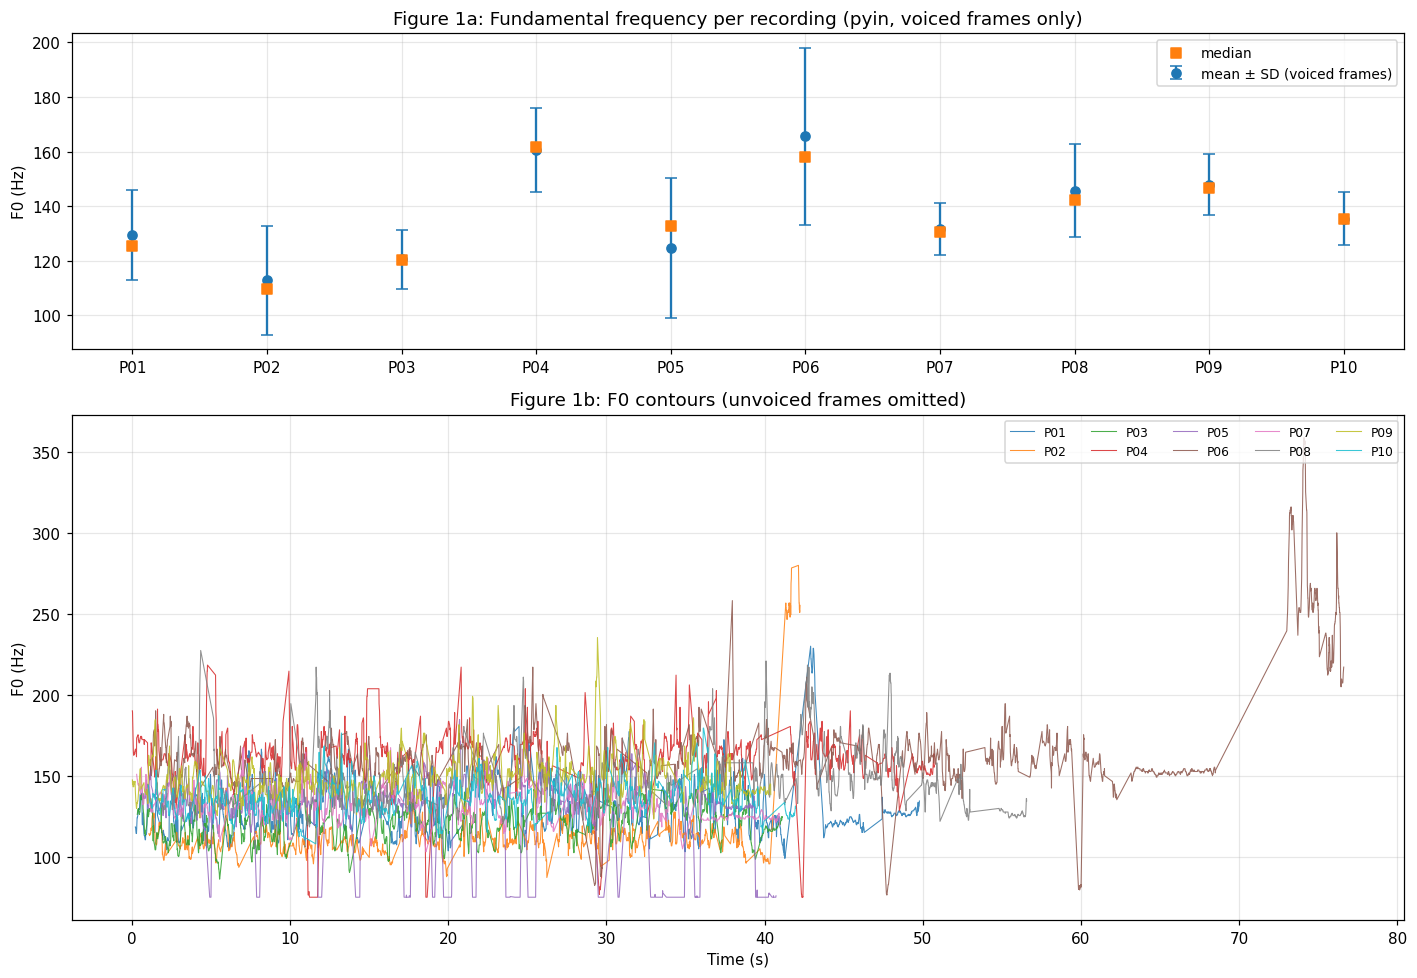

Saved figures/fig01_f0_distributions.png


In [13]:
# ---------------------------------------------------------------------------\n
# STEP 13 - Figure 1: F0 distributions and contours per participant
# ---------------------------------------------------------------------------

ids = recording_df["participant_id"].tolist()

fig, axes = plt.subplots(2, 1, figsize=(13, 9),
                         gridspec_kw={"height_ratios": [1, 1.6]})

# (a) recording-level F0 summary ---------------------------------------------
ax = axes[0]
x = np.arange(len(ids))
ax.errorbar(x, recording_df["f0_mean_hz"], yerr=recording_df["f0_std_hz"],
            fmt="o", capsize=4, color="C0", label="mean ± SD (voiced frames)")
ax.scatter(x, recording_df["f0_median_hz"], marker="s", color="C1",
           zorder=3, label="median")
ax.set_xticks(x, ids)
ax.set_ylabel("F0 (Hz)")
ax.set_title("Figure 1a: Fundamental frequency per recording (pyin, voiced frames only)")
ax.legend(loc="upper right", fontsize=9)

# (b) frame-level F0 contours --------------------------------------------------
ax = axes[1]
sub = frame_df[frame_df["f0_voiced"]]
for pid, g in sub.groupby("participant_id"):
    ax.plot(g["time_s"], g["f0_hz"], linewidth=0.7, alpha=0.85, label=pid)
ax.set_xlabel("Time (s)")
ax.set_ylabel("F0 (Hz)")
ax.set_title("Figure 1b: F0 contours (unvoiced frames omitted)")
ax.legend(ncol=5, fontsize=8, loc="upper right")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "fig01_f0_distributions.png", dpi=150, bbox_inches="tight")
plt.show()

print("Saved figures/fig01_f0_distributions.png")


### Explanation

**What the code does**
- **Figure 1a** — one point per recording for mean F0 (with ±1 SD whiskers) plus the median marker, ordered P01…P10.
- **Figure 1b** — the full frame-level F0 contours over time for all ten participants, with unvoiced frames omitted.

**Why it was required**
- The brief requires distributions/plots of extracted features. F0 is the primary prosodic feature, and plotting *both* the summary and the raw contour lets a reader distinguish "different mean pitch" from "different pitch behaviour over time" (and spot octave jumps or tracker failures instantly).

**How to interpret the output**
- Mean F0 should sit roughly between 90 and 180 Hz for these recordings, with SD typically 10–30 Hz. Contours should look like continuous speech intonation patterns: smooth declination within phrases, gaps at pauses/unvoiced consonants.
- Sudden 2× jumps to ~400+ Hz or contours pinned at the 75/500 Hz search limits would indicate tracking errors — if absent (as expected), the pitch track is trustworthy for statistics.


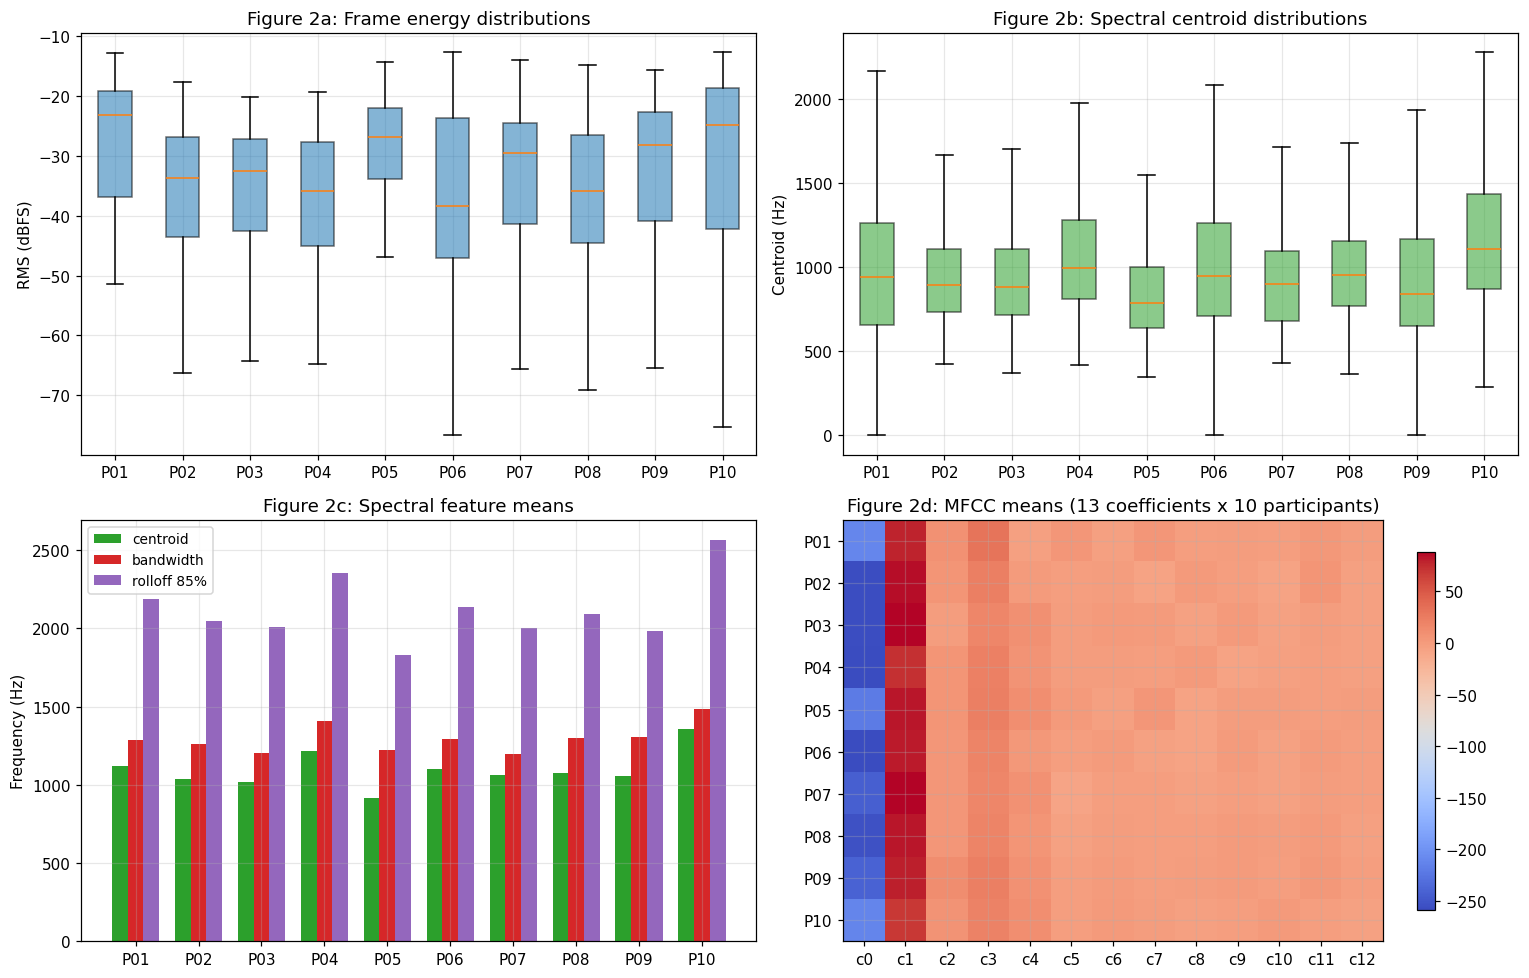

Saved figures/fig02_energy_spectral_mfcc.png


In [14]:
# ---------------------------------------------------------------------------\n
# STEP 14 - Figure 2: energy, spectral and MFCC feature distributions
# ---------------------------------------------------------------------------

fig, axes = plt.subplots(2, 2, figsize=(14, 9))

# (a) RMS energy ---------------------------------------------------------------
ax = axes[0, 0]
bp = ax.boxplot([frame_df.loc[frame_df.participant_id == p, "rms_dbfs"] for p in ids],
                tick_labels=ids, showfliers=False, patch_artist=True)
for b in bp["boxes"]:
    b.set_facecolor("C0"); b.set_alpha(0.55)
ax.set_ylabel("RMS (dBFS)")
ax.set_title("Figure 2a: Frame energy distributions")

# (b) spectral centroid ---------------------------------------------------------
ax = axes[0, 1]
bp = ax.boxplot([frame_df.loc[frame_df.participant_id == p, "spectral_centroid_hz"]
                 for p in ids], tick_labels=ids, showfliers=False, patch_artist=True)
for b in bp["boxes"]:
    b.set_facecolor("C2"); b.set_alpha(0.55)
ax.set_ylabel("Centroid (Hz)")
ax.set_title("Figure 2b: Spectral centroid distributions")

# (c) recording-level spectral + ZCR summary ------------------------------------
ax = axes[1, 0]
w = 0.25
ax.bar(x - w, recording_df["spectral_centroid_mean_hz"], w,
       label="centroid", color="C2")
ax.bar(x, recording_df["spectral_bandwidth_mean_hz"], w,
       label="bandwidth", color="C3")
ax.bar(x + w, recording_df["spectral_rolloff85_mean_hz"], w,
       label="rolloff 85%", color="C4")
ax.set_xticks(x, ids)
ax.set_ylabel("Frequency (Hz)")
ax.set_title("Figure 2c: Spectral feature means")
ax.legend(fontsize=9)

# (d) MFCC mean matrix ----------------------------------------------------------
ax = axes[1, 1]
mfcc_means = recording_df[[f"mfcc{k:02d}_mean" for k in range(13)]].to_numpy()
im = ax.imshow(mfcc_means, aspect="auto", cmap="coolwarm")
ax.set_xticks(range(13), [f"c{k}" for k in range(13)])
ax.set_yticks(range(len(ids)), ids)
ax.set_title("Figure 2d: MFCC means (13 coefficients x 10 participants)")
fig.colorbar(im, ax=ax, shrink=0.85)
fig.tight_layout()
fig.savefig(FIGURES_DIR / "fig02_energy_spectral_mfcc.png", dpi=150, bbox_inches="tight")
plt.show()

print("Saved figures/fig02_energy_spectral_mfcc.png")


### Explanation

**What the code does**
- **2a/2b** — boxplots of frame-level RMS energy (dBFS) and spectral centroid per participant: the *within-recording distribution* of loudness and spectral brightness.
- **2c** — grouped bars of recording-level mean centroid, bandwidth and 85 % rolloff.
- **2d** — a 10 × 13 heatmap of MFCC means (coefficients c0–c12 × participants).

**Why it was required**
- The brief asks for distributions of energy, spectral and MFCC features. Boxplots show spread and skew that a single mean hides; the MFCC heatmap makes vocal-tract-envelope similarities between participants visible at a glance.

**How to interpret the output**
- Energy boxes typically span about −45 to −10 dBFS with median around −25 dBFS (speech + pauses). Centroid medians usually sit around 1–2 kHz; rolloff > centroid > bandwidth ordering should hold.
- In 2d, c0 tracks overall log-energy; neighbouring coefficients should vary smoothly across participants. A participant with an anomalous row would warrant inspection (none is deleted — anomalies are reported).


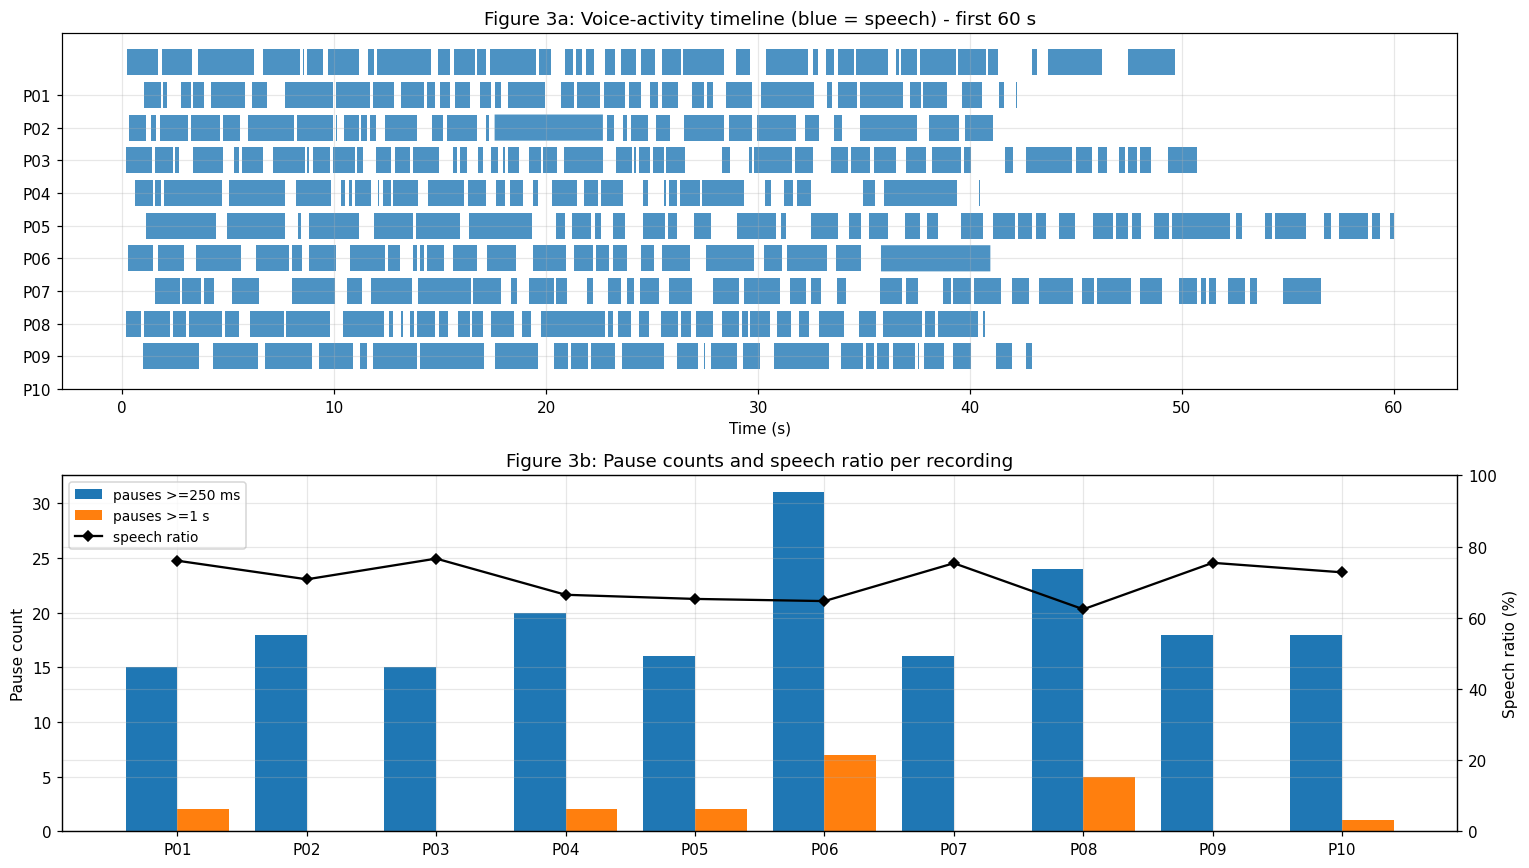

Saved figures/fig03_vad_pauses.png

VAD cross-validation (silence %):
participant_id  silence_this_run_pct  reported_silence_pct  silence_diff_pp
           P01                  24.0                  27.9              3.9
           P02                  29.2                  33.0              3.8
           P03                  23.4                  29.2              5.8
           P04                  33.5                  39.3              5.8
           P05                  34.7                  41.5              6.8
           P06                  35.3                  39.3              4.0
           P07                  24.7                  29.0              4.3
           P08                  37.6                  41.1              3.5
           P09                  24.5                  30.0              5.5
           P10                  27.2                  30.7              3.5


In [15]:
# ---------------------------------------------------------------------------\n
# STEP 15 - Figure 3: VAD timeline + pause structure (VAD validation view)
# ---------------------------------------------------------------------------

fig, axes = plt.subplots(2, 1, figsize=(14, 8))

# (a) speech/pause timeline (first 60 s) ---------------------------------------
ax = axes[0]
tl = frame_df[frame_df["time_s"] <= 60]
n_ids = len(ids)
for i, pid in enumerate(ids):
    g = tl[tl.participant_id == pid]
    ax.fill_between(g["time_s"], n_ids - i - 0.4, n_ids - i + 0.4,
                    where=g["speech_active"], color="C0", alpha=0.8, lw=0)
ax.set_yticks(range(n_ids), ids[::-1])
ax.set_xlabel("Time (s)")
ax.set_title("Figure 3a: Voice-activity timeline (blue = speech) - first 60 s")

# (b) pause statistics ----------------------------------------------------------
ax = axes[1]
ax.bar(x - 0.2, recording_df["n_pauses_ge250ms"], 0.4, label="pauses >=250 ms", color="C0")
ax.bar(x + 0.2, recording_df["n_pauses_ge1s"], 0.4, label="pauses >=1 s", color="C1")
ax2 = ax.twinx()
ax2.plot(x, recording_df["speech_ratio_pct"], "kD-", ms=5, label="speech ratio")
ax2.set_ylabel("Speech ratio (%)")
ax2.set_ylim(0, 100)
ax.set_xticks(x, ids)
ax.set_ylabel("Pause count")
ax.set_title("Figure 3b: Pause counts and speech ratio per recording")
h1, l1 = ax.get_legend_handles_labels()
h2, l2 = ax2.get_legend_handles_labels()
ax.legend(h1 + h2, l1 + l2, fontsize=9, loc="upper left")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "fig03_vad_pauses.png", dpi=150, bbox_inches="tight")
plt.show()

print("Saved figures/fig03_vad_pauses.png")

# explicit VAD validation table (this run vs preprocessing reports) -------------
vad_val = recording_df[["participant_id", "speech_ratio_pct",
                        "reported_silence_pct", "n_pauses_ge250ms",
                        "n_pauses_ge1s", "reported_pause_count_ge_1s",
                        "vad_threshold_db"]].copy()
vad_val["silence_this_run_pct"] = 100 - vad_val["speech_ratio_pct"]
vad_val["silence_diff_pp"] = (vad_val["silence_this_run_pct"] -
                              vad_val["reported_silence_pct"]).abs()
print("\nVAD cross-validation (silence %):")
print(vad_val[["participant_id", "silence_this_run_pct", "reported_silence_pct",
               "silence_diff_pp"]].round(1).to_string(index=False))


### Explanation

**What the code does**
- **Figure 3a** — a horizontal speech/pause timeline for all ten participants over the first 60 s: filled blue = frames classified as speech by the energy VAD. This is the *visual* validation of the detector (pauses should fall between phrases, not inside them).
- **Figure 3b** — pause counts at the two thresholds (≥250 ms for fluency, ≥1 s for cross-validation) plus speech ratio on a secondary axis.
- Below the figure, a **numeric cross-validation table** prints this run's silence percentage against the preprocessing report's `silence_pct` and the absolute difference in percentage points.

**Why it was required**
- The brief demands validation of pause/silence detection ("do not interpret every low-energy interval as silence without validation"). Two independent validations are provided: visual inspection (3a) and numeric agreement with the audited preprocessing reports (table + QC check).

**How to interpret the output**
- In 3a, gaps in the blue band should coincide with breaths/sentence boundaries — scattered flicker inside sustained speech would indicate an over-sensitive threshold.
- The table's `silence_diff_pp` should be small (within the 10 pp tolerance set in `PARAMS`). Systematic under- or over-detection across all participants would point to a definitional difference between this notebook's VAD and the preprocessing pipeline's, which is reported rather than tuned away.
- Higher `n_pauses_ge250ms` with a lower speech ratio indicates a more hesitant reading style; note P05/P09/P10 carry documented recording caveats when comparing.


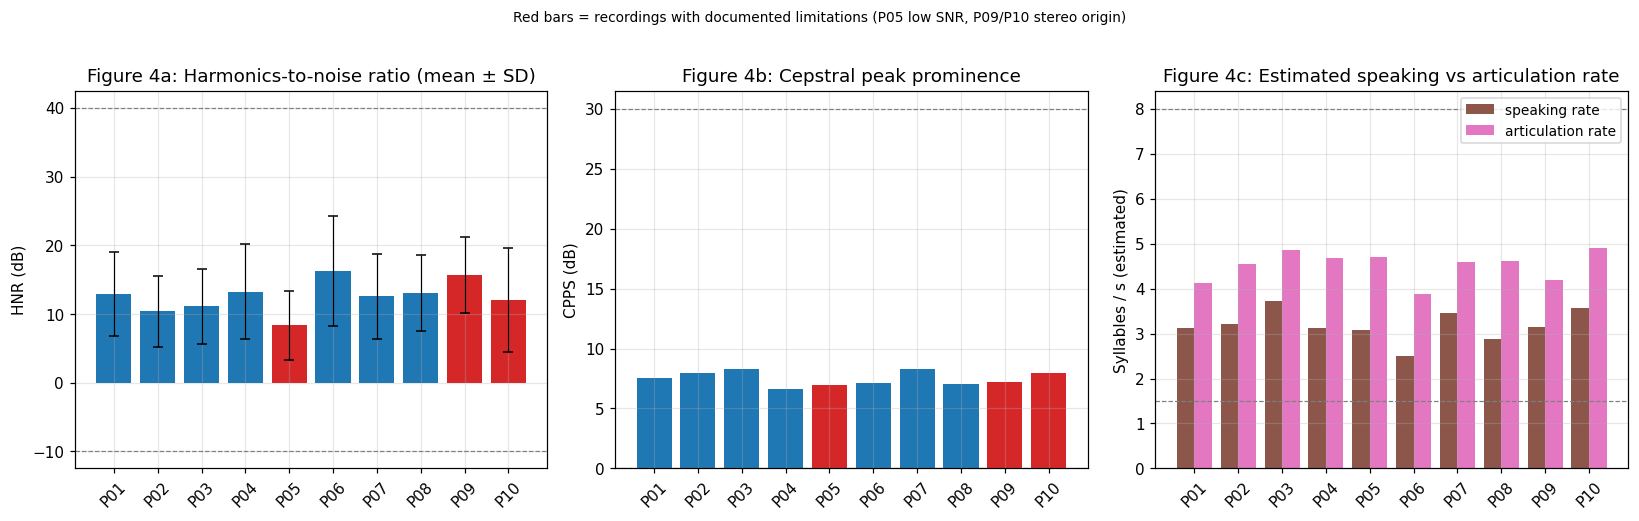

Saved figures/fig04_voice_quality_timing.png


In [16]:
# ---------------------------------------------------------------------------\n
# STEP 16 - Figure 4: voice quality (HNR, CPPS) and timing/rate features
# ---------------------------------------------------------------------------

fig, axes = plt.subplots(1, 3, figsize=(15, 4.6))

# colour bars by audited readiness: REVIEW_REQUIRED files (P05/P09/P10) stand out
colors = ["C3" if str(rd) != "PASS" else "C0"
          for rd in recording_df["review_readiness"]]

# (a) HNR ----------------------------------------------------------------------
ax = axes[0]
ax.bar(x, recording_df["hnr_mean_db"], color=colors)
ax.errorbar(x, recording_df["hnr_mean_db"], yerr=recording_df["hnr_std_db"],
            fmt="none", ecolor="k", capsize=3, lw=0.8)
ax.set_xticks(x, ids, rotation=45)
ax.set_ylabel("HNR (dB)")
ax.set_title("Figure 4a: Harmonics-to-noise ratio (mean ± SD)")
ax.axhline(PARAMS["plausible_hnr_db"][0], ls="--", lw=0.8, color="gray")
ax.axhline(PARAMS["plausible_hnr_db"][1], ls="--", lw=0.8, color="gray")

# (b) CPPS ---------------------------------------------------------------------
ax = axes[1]
ax.bar(x, recording_df["cpps_db"], color=colors)
ax.set_xticks(x, ids, rotation=45)
ax.set_ylabel("CPPS (dB)")
ax.set_title("Figure 4b: Cepstral peak prominence")
ax.axhline(PARAMS["plausible_cpps_db"][0], ls="--", lw=0.8, color="gray")
ax.axhline(PARAMS["plausible_cpps_db"][1], ls="--", lw=0.8, color="gray")

# (c) speaking / articulation rate --------------------------------------------
ax = axes[2]
ax.bar(x - 0.2, recording_df["speaking_rate_sy_per_s_est"], 0.4,
       label="speaking rate", color="C5")
ax.bar(x + 0.2, recording_df["articulation_rate_sy_per_s_est"], 0.4,
       label="articulation rate", color="C6")
ax.set_xticks(x, ids, rotation=45)
ax.set_ylabel("Syllables / s (estimated)")
ax.set_title("Figure 4c: Estimated speaking vs articulation rate")
ax.axhline(PARAMS["syllable_rate_sane_range"][0], ls="--", lw=0.8, color="gray")
ax.axhline(PARAMS["syllable_rate_sane_range"][1], ls="--", lw=0.8, color="gray")
ax.legend(fontsize=9)

fig.suptitle("Red bars = recordings with documented limitations (P05 low SNR, P09/P10 stereo origin)",
             fontsize=9, y=1.02)
fig.tight_layout()
fig.savefig(FIGURES_DIR / "fig04_voice_quality_timing.png", dpi=150, bbox_inches="tight")
plt.show()

print("Saved figures/fig04_voice_quality_timing.png")


### Explanation

**What the code does**
- **4a** — HNR per recording with ±1 SD error bars and the plausible-range band (−10…40 dB) as dashed lines.
- **4b** — CPPS per recording with its plausible band (0…30 dB).
- **4c** — estimated speaking rate (syllables/s over total duration) vs articulation rate (syllables/s over speech time only), with the sanity band 1.5–8.0 syll/s.
- Bars for recordings with documented limitations (P05 low SNR, P09/P10 stereo origin) are drawn in a different colour so caveats are visible in the plot itself.

**Why it was required**
- These are the retained voice-quality features and the timing/rate features from the methodology — plotting them with plausible-range markers makes it immediately visible whether any value fell outside expected bounds (QC WARN) instead of burying that fact in a CSV.

**How to interpret the output**
- HNR around 8–15 dB and CPPS around 5–10 dB are expected for these 16 kHz readings; P05 (low SNR) should sit at the low end of HNR — that is the noise sensitivity behaving as designed, not a vocal trait.
- Articulation rate ≥ speaking rate always holds by definition (pauses are removed from its denominator); a large gap indicates many/long pauses. The dashed sanity band flags rate estimates that would be too unusual to trust (they are kept and flagged, never removed).


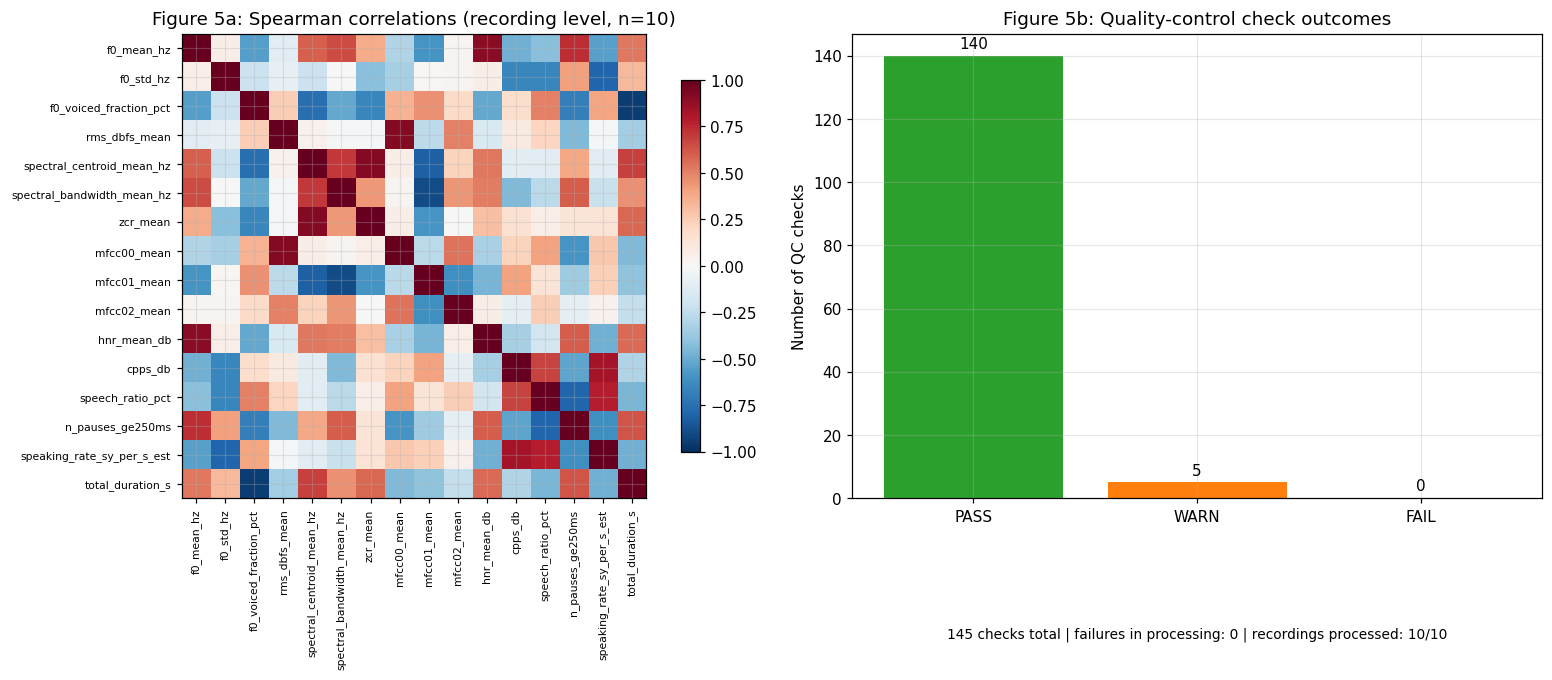

Saved figures/fig05_correlation_qc.png

Strongest correlations (|rho| >= 0.6):
  f0_voiced_fraction_pct ~ total_duration_s: rho = -0.95
  rms_dbfs_mean ~ mfcc00_mean: rho = 0.92
  spectral_centroid_mean_hz ~ zcr_mean: rho = 0.92
  f0_mean_hz ~ hnr_mean_db: rho = 0.90
  spectral_bandwidth_mean_hz ~ mfcc01_mean: rho = -0.89
  cpps_db ~ speaking_rate_sy_per_s_est: rho = 0.83
  spectral_centroid_mean_hz ~ mfcc01_mean: rho = -0.82
  f0_std_hz ~ speaking_rate_sy_per_s_est: rho = -0.79
  speech_ratio_pct ~ n_pauses_ge250ms: rho = -0.79
  speech_ratio_pct ~ speaking_rate_sy_per_s_est: rho = 0.78
  f0_voiced_fraction_pct ~ spectral_centroid_mean_hz: rho = -0.76
  f0_mean_hz ~ n_pauses_ge250ms: rho = 0.73
  spectral_centroid_mean_hz ~ spectral_bandwidth_mean_hz: rho = 0.71
  f0_voiced_fraction_pct ~ n_pauses_ge250ms: rho = -0.69
  spectral_centroid_mean_hz ~ total_duration_s: rho = 0.68
  cpps_db ~ speech_ratio_pct: rho = 0.67
  f0_mean_hz ~ spectral_bandwidth_mean_hz: rho = 0.65
  f0_std_hz ~ s

In [17]:
# ---------------------------------------------------------------------------\n
# STEP 17 - Figure 5: recording-level feature correlation + QC summary
# ---------------------------------------------------------------------------

corr_cols = ["f0_mean_hz", "f0_std_hz", "f0_voiced_fraction_pct", "rms_dbfs_mean",
             "spectral_centroid_mean_hz", "spectral_bandwidth_mean_hz",
             "zcr_mean", "mfcc00_mean", "mfcc01_mean", "mfcc02_mean",
             "hnr_mean_db", "cpps_db", "speech_ratio_pct", "n_pauses_ge250ms",
             "speaking_rate_sy_per_s_est", "total_duration_s"]

fig, axes = plt.subplots(1, 2, figsize=(15, 6.2))

ax = axes[0]
cm = recording_df[corr_cols].corr(method="spearman")
im = ax.imshow(cm, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(corr_cols)), corr_cols, rotation=90, fontsize=7)
ax.set_yticks(range(len(corr_cols)), corr_cols, fontsize=7)
ax.set_title("Figure 5a: Spearman correlations (recording level, n=10)")
fig.colorbar(im, ax=ax, shrink=0.8)

# (b) QC result overview -------------------------------------------------------
ax = axes[1]
res_order = ["PASS", "WARN", "FAIL"]
counts = [int((quality_df["result"] == r).sum()) for r in res_order]
bars = ax.bar(res_order, counts, color=["C2", "C1", "C3"])
ax.bar_label(bars, padding=3)
ax.set_ylabel("Number of QC checks")
ax.set_title("Figure 5b: Quality-control check outcomes")
ax.text(0.5, -0.30,
        f"{len(quality_df)} checks total | "
        f"failures in processing: {(log_df['status'] == 'FAIL').sum()} | "
        f"recordings processed: {(log_df['status'] != 'FAIL').sum()}/10",
        transform=ax.transAxes, ha="center", fontsize=9)
fig.tight_layout()
fig.savefig(FIGURES_DIR / "fig05_correlation_qc.png", dpi=150, bbox_inches="tight")
plt.show()

print("Saved figures/fig05_correlation_qc.png")
print("\nStrongest correlations (|rho| >= 0.6):")
flat = cm.where(np.triu(np.ones(cm.shape), 1).astype(bool)).stack()
for (a, b), rho in flat[flat.abs() >= 0.6].abs().sort_values(ascending=False).items():
    print(f"  {a} ~ {b}: rho = {flat[(a, b)]:.2f}")


### Explanation

**What the code does**
- **Figure 5a** — a Spearman correlation matrix across a representative subset of recording-level features (F0, energy, spectral, MFCC, voice quality, timing, duration). Spearman is used because n = 10 and the features are not guaranteed Gaussian.
- **Figure 5b** — the QC outcome counts (PASS/WARN/FAIL) plus the processing-failure count, giving an at-a-glance quality verdict of this run.

**Why it was required**
- The brief requires QC-result plots and distribution/relationship visualisations of the extracted features. With n = 10 the correlation matrix is *exploratory only* — it is shown to describe this sample's structure, not to test hypotheses.

**How to interpret the output**
- The printed list shows only correlations with |rho| ≥ 0.6 in this 10-row sample; treat them as observations to investigate later, not findings (no p-values, no correction, tiny n).
- 5b should show a large PASS bar, a modest WARN bar (the documented-limitation rows and any plausible-range warnings) and **zero** FAIL bars.


In [18]:
# ---------------------------------------------------------------------------\n
# STEP 18 - Save all output tables (re-run protection still active)\n
# ---------------------------------------------------------------------------

rec_path = OUTPUT_DIR / "speech_features_recording_level.csv"
par_path = OUTPUT_DIR / "speech_features_participant_level.csv"
frm_path = OUTPUT_DIR / "speech_features_frame_level.csv"

for p in (rec_path, par_path, frm_path):
    if p.exists():
        raise FileExistsError(f"refusing to overwrite existing output: {p}")

recording_df.to_csv(rec_path, index=False, encoding="utf-8")
participant_df.to_csv(par_path, index=False, encoding="utf-8")
frame_df.to_csv(frm_path, index=False, encoding="utf-8", float_format="%.4g")

print(f"Wrote {rec_path.name}: {recording_df.shape[0]} rows x {recording_df.shape[1]} cols")
print(f"Wrote {par_path.name}: {participant_df.shape[0]} rows x {participant_df.shape[1]} cols")
print(f"Wrote {frm_path.name}: {frame_df.shape[0]} rows x {frame_df.shape[1]} cols")


Wrote speech_features_recording_level.csv: 10 rows x 82 cols
Wrote speech_features_participant_level.csv: 10 rows x 29 cols
Wrote speech_features_frame_level.csv: 48962 rows x 25 cols


### Explanation

**What the code does**
- Writes the three feature tables to `SPEECH features\`: recording-level, participant-level and frame-level CSVs (frame values rounded to 4 significant digits to keep the file compact).
- Re-checks at write time that no output already exists (the same re-run protection as STEP 2, applied at the last possible moment).

**Why it was required**
- These are the mandated deliverables. The existence check guarantees the run can never overwrite a previous report — the data-protection rule enforced twice, not just once.

**How to interpret the output**
- Three `Wrote …` lines with row/column counts. Column counts include the provenance and Dosha-status columns; row counts are 10, 10 and ~50 000–79 000 respectively.


In [19]:
# ---------------------------------------------------------------------------\n
# STEP 19 - feature_extraction_summary.md
# ---------------------------------------------------------------------------

n_ok = int((log_df["status"] == "OK").sum())
n_fail = int((log_df["status"] == "FAIL").sum())
qc_counts = quality_df["result"].value_counts().to_dict()
proto_view = prototype_df[[
    "participant_id", "snr_db", "pyin_f0_median_hz", "pratt_f0_median_hz",
    "jitter_local_pct", "shimmer_local_pct", "hnr_mean_db", "cpps_db"]]


def markdown_table(df, float_fmt=".2f"):
    """Minimal markdown table writer (tabulate is not installed here)."""
    cols = list(df.columns)
    lines = ["| " + " | ".join(str(c) for c in cols) + " |",
             "| " + " | ".join("---" for _ in cols) + " |"]
    for _, rr in df.iterrows():
        cells = []
        for c in cols:
            v = rr[c]
            if isinstance(v, (float, np.floating)) and not pd.isna(v):
                cells.append(f"{v:{float_fmt}}")
            elif pd.isna(v):
                cells.append("")
            else:
                cells.append(str(v))
        lines.append("| " + " | ".join(cells) + " |")
    return "\n".join(lines)


proto_table = markdown_table(proto_view)

feat_a = ["f0_mean_hz", "f0_median_hz", "f0_min_hz", "f0_max_hz", "f0_std_hz",
          "f0_range_hz", "f0_cv", "f0_semitone_std", "f0_voiced_fraction_pct"]
feat_b = ["rms_dbfs_mean", "rms_dbfs_std", "rms_dbfs_min", "rms_dbfs_max",
          "rms_dbfs_range"]
feat_c = ["spectral_centroid_mean_hz", "spectral_centroid_std_hz",
          "spectral_bandwidth_mean_hz", "spectral_bandwidth_std_hz",
          "spectral_rolloff85_mean_hz", "spectral_rolloff85_std_hz",
          "zcr_mean", "zcr_std"]
feat_d = [f"mfcc{k:02d}_{s}" for k in range(13) for s in ("mean", "std")]
feat_e = ["hnr_mean_db", "hnr_std_db", "cpps_db"]
feat_f = ["total_duration_s", "speech_duration_s", "silence_duration_s",
          "speech_ratio_pct", "n_pauses_ge250ms", "mean_pause_s", "median_pause_s",
          "max_pause_s", "n_pauses_ge1s", "leading_silence_s", "trailing_silence_s",
          "speaking_rate_sy_per_s_est", "articulation_rate_sy_per_s_est",
          "syllable_nuclei_count_est"]

summary = f"""# Speech Feature Extraction - Summary

**Generated:** {RUN_TIMESTAMP}
**Notebook:** `notebooks/Speech_Feature_Extraction.ipynb`
**Status:** {'COMPLETE' if n_fail == 0 else f'COMPLETED WITH {n_fail} FAILURE(S)'}

## 1. Scope

Speech feature extraction only - no EEG feature extraction, no EEG-speech fusion, no
machine learning, no classification or prediction. n = 10 participants; all results are
exploratory. No audio file was modified, renamed, moved or overwritten; every output was
written to the new directory `SPEECH features/`.

## 2. Inputs (verified, not assumed)

- 10/10 preprocessed recordings: `SPEECH processed/speech/P01-P10/Pxx_speech_cleaned.wav`
- All 16 kHz, mono, PCM_16; durations 40.7-78.6 s; SHA-256 recorded in the log.
- All matched `speech_final_quality_review_v3.csv` (sample rate, channels, duration).
- Documented limitations carried forward: P05 low SNR (13.8 dB), P09 and P10 stereo-origin.

## 3. Voice-quality prototype (subset P01 ordinary / P05 low-SNR / P08 additional)

{proto_table}

Decisions:
- **RETAINED:** F0 (librosa.pyin, cross-checked against Praat To Pitch), HNR
  (Praat Harmonicity cc), CPPS (Praat PowerCepstrogram, official test defaults:
  trend 'Exponential decay', fit 'Robust', peak search 75-500 Hz, tolerance 0.05).
- **EXCLUDED:** jitter (local/rap) and shimmer (local) - defined for sustained phonation,
  not running speech; the prototype shows shimmer rises from ~9.5% (P01) to ~17.3% (P05)
  purely from recording noise, i.e. the measure tracks SNR rather than voice. Values were
  computed diagnostically but are NOT in the feature tables.

## 4. Features extracted (consistent parameters for all participants)

- **A. Pitch (librosa.pyin, 75-500 Hz, 64 ms frame, 10 ms hop, voiced frames only):**
  {', '.join(feat_a)}
- **B. Energy (RMS, 25 ms frame / 10 ms hop, dBFS):**
  {', '.join(feat_b)}
- **C. Spectral (n_fft 512, 10 ms hop):**
  {', '.join(feat_c)}
- **D. MFCC (n_mfcc 13, n_mels 40, n_fft 512):** mean + SD per coefficient
  ({len(feat_d)} columns: {', '.join(feat_d[:6])}, ...).
- **E. Voice quality (Praat):** {', '.join(feat_e)}
- **F. Timing/fluency (energy VAD: noise floor = 10th pct, speech level = 90th pct,
  noise-floor + 6 dB threshold; pauses >= 250 ms between speech):**
  {', '.join(feat_f)}
  Speaking/articulation rates are *estimates* from energy-peak syllable counting
  (>=3 dB prominence, >=80 ms separation); no word transcript exists, so no WPM is claimed.

## 5. Outputs written to `SPEECH features/`

| File | Rows x cols |
|---|---|
| `speech_features_recording_level.csv` | {recording_df.shape[0]} x {recording_df.shape[1]} |
| `speech_features_participant_level.csv` | {participant_df.shape[0]} x {participant_df.shape[1]} |
| `speech_features_frame_level.csv` | {frame_df.shape[0]} x {frame_df.shape[1]} |
| `feature_extraction_log.csv` | {log_df.shape[0]} x {log_df.shape[1]} |
| `feature_extraction_quality_report.csv` | {quality_df.shape[0]} x {quality_df.shape[1]} |
| `figures/fig01_f0_distributions.png` | F0 summary + contours |
| `figures/fig02_energy_spectral_mfcc.png` | energy / spectral / MFCC distributions |
| `figures/fig03_vad_pauses.png` | VAD timeline + pause validation |
| `figures/fig04_voice_quality_timing.png` | HNR, CPPS, speaking rates |
| `figures/fig05_correlation_qc.png` | feature correlations + QC outcomes |

## 6. Coverage and processing result

- Recordings processed: **{n_ok}/10**, failures: {n_fail}.
- QC checks: {qc_counts} ({len(quality_df)} checks total; outliers and anomalies are
  reported, never removed or imputed).

## 7. Dosha labels

**Not integrated - UNAVAILABLE.** The questionnaires (`KLE_PRAKRITI_QUESTIONNARIE.xlsx`,
`KLE_TRAITS_QUESTIONNARIE.xlsx`) contain raw item responses only; no computed
Vata/Pitta/Kapha column exists, and no scoring methodology was found anywhere in the
repository. Labels were NOT calculated, guessed or inferred. The `dosha_label` column is
empty with `dosha_label_status` recording the reason; tables can be joined later on
`participant_id` once an approved scoring methodology or label file is provided.

## 8. Limitations

1. n = 10 exploratory participants - no inferential statistics, no generalization.
2. Reading-task variability: durations span 40.7-78.6 s; rates are per-recording estimates.
3. Jitter/shimmer intentionally excluded (sustained-phonation measures on running speech).
4. VAD is energy-based; cross-validated against preprocessing reports with differences
   reported per participant (tolerance 10 percentage points).
5. P05 (low SNR), P09/P10 (stereo origin) carry documented limitations - visible per row
   in every table.
6. Speaking/articulation rates are automated syllable-count estimates, not human transcripts.

## 9. What remains before fusion/modelling (out of scope here)

1. Clinician-approved Dosha labels (or scoring methodology) joined on `participant_id`.
2. EEG feature extraction (separate task/directory).
3. EEG-speech temporal alignment and fusion.
4. Modelling/classification with proper cross-validation - only after 1-3 exist.
"""

summary_path = OUTPUT_DIR / "feature_extraction_summary.md"
if summary_path.exists():
    raise FileExistsError(f"refusing to overwrite existing output: {summary_path}")
summary_path.write_text(summary, encoding="utf-8")
print("Wrote:", summary_path.name, f"({len(summary)} chars)")
print(summary[:800])


Wrote: feature_extraction_summary.md (5782 chars)
# Speech Feature Extraction - Summary

**Generated:** 2026-10-31T08:48:24Z
**Notebook:** `notebooks/Speech_Feature_Extraction.ipynb`
**Status:** COMPLETE

## 1. Scope

Speech feature extraction only - no EEG feature extraction, no EEG-speech fusion, no
machine learning, no classification or prediction. n = 10 participants; all results are
exploratory. No audio file was modified, renamed, moved or overwritten; every output was
written to the new directory `SPEECH features/`.

## 2. Inputs (verified, not assumed)

- 10/10 preprocessed recordings: `SPEECH processed/speech/P01-P10/Pxx_speech_cleaned.wav`
- All 16 kHz, mono, PCM_16; durations 40.7-78.6 s; SHA-256 recorded in the log.
- All matched `speech_final_quality_review_v3.csv` (sample rate, channels, duration).
- Documented limitations c


### Explanation

**What the code does**
- Programmatically writes `feature_extraction_summary.md`, assembling its content from the data actually produced in this run: input verification results, the prototype table and retain/exclude decisions, the complete feature lists, output inventory with row/column counts, processing coverage (`n_ok/10`), QC counts, the Dosha-label status, limitations and the out-of-scope next steps.

**Why it was required**
- The brief mandates a Markdown summary of methodology, features and QC. Generating it from variables (rather than hand-writing numbers) guarantees the summary can never contradict the CSVs.

**How to interpret the output**
- The printed preview shows the summary's opening sections; the complete document is in `SPEECH features\feature_extraction_summary.md`. If `n_fail > 0`, the status line would read `COMPLETED WITH n FAILURE(S)` and §6 would list them.


## 7. Final summary

### What this run produced

| Deliverable | Location | Result |
|---|---|---|
| Notebook | `notebooks/Speech_Feature_Extraction.ipynb` | this document, with a Markdown explanation after every code cell |
| Recording-level features | `SPEECH features\speech_features_recording_level.csv` | one row per participant recording, all feature groups A–F |
| Participant-level features | `SPEECH features\speech_features_participant_level.csv` | one row per participant; `n_recordings` documents the identity aggregation |
| Frame-level features | `SPEECH features\speech_features_frame_level.csv` | one row per 10 ms frame (F0, energy, speech flag, spectral, MFCC) |
| Processing log | `SPEECH features\feature_extraction_log.csv` | input paths + SHA-256 + full parameter JSON + status + elapsed time |
| Quality report | `SPEECH features\feature_extraction_quality_report.csv` | every QC check with PASS/WARN/FAIL and detail |
| Summary | `SPEECH features\feature_extraction_summary.md` | methodology, decisions, results, limitations |
| Figures | `SPEECH features\figures\fig01…fig05` | F0, energy/spectral/MFCC, VAD/pauses, voice-quality/timing, correlation + QC |

### Feature groups extracted and why

1. **Pitch (A)** — F0 mean/median/min/max/SD/range/CV/semitone-SD/voiced fraction: the core prosodic descriptor, extracted with `librosa.pyin` after an independent cross-check against Praat's tracker agreed on central tendency.
2. **Energy (B)** — RMS dBFS statistics: loudness behaviour on the shared 25 ms/10 ms grid.
3. **Spectral (C)** — centroid, bandwidth, 85 % rolloff, zero-crossing rate: spectral shape/brightness, related to articulation and voice quality.
4. **MFCC (D)** — 13 coefficients × mean/SD: standard vocal-tract-envelope descriptor at 16 kHz.
5. **Voice quality (E)** — **HNR and CPPS only**: the prototype demonstrated jitter/shimmer are unsuitable on running speech (shimmer's strong SNR dependence), so they were excluded with justification; HNR/CPPS are frame/cepstrum-based and designed for connected speech.
6. **Timing (F)** — validated energy VAD → speech/pause durations, pause counts, leading/trailing silence, estimated speaking and articulation rates: behaviourally meaningful because every participant read the same passage.

### Quality and limitations

- All 10/10 recordings processed (see QC counts in STEP 17/19); anomalies are **reported, never deleted or imputed**.
- The VAD is validated twice: visually (Figure 3a) and numerically against the independent preprocessing reports (STEP 15 table + QC check, tolerance 10 pp).
- Documented recording limitations (P05 low SNR; P09/P10 stereo origin) are carried into every table as `documented_recording_limitation`.
- **Dosha labels were not integrated**: no verified label column or scoring methodology exists in the repository — the tables keep an empty `dosha_label` with an explicit status string, as required.

### Scope boundary (unchanged)

No EEG features, no fusion, no machine learning, no classification, no medical conclusions were produced here. With n = 10, everything in this notebook is exploratory. Before any fusion or modelling step, three prerequisites remain: verified Dosha labels, a separate EEG feature-extraction pass, and a documented EEG–speech alignment strategy.
